In [1]:
import numpy as np
import os

path = "/projects/static2dynamic/Gravier/schron/notebooks/eb_data.npy"

if os.path.exists(path):
    data = np.load(path)
    print("Shape:", data.shape)
else:
    print("File not found:", path)


Shape: (5, 300, 5)


# VAE Experiments

---

In [5]:
import os

In [6]:
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

# Imports

In [2]:
import torch
from diffusers.pipelines.pipeline_utils import DiffusionPipeline
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torch import Tensor
from pathlib import Path
import tqdm.notebook as tqdm
import numpy as np
import matplotlib.pyplot as plt
from torchvision.transforms import (
    Compose,
    ConvertImageDtype,
    PILToTensor,
    Normalize,
    Resize,
)

In [3]:
torch.set_grad_enabled(False)

# Download SD3 vae

In [2]:
device = "cuda:0"

In [6]:
pipe = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-2-base",
)
vae = pipe.vae.to(device)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

# Biotine dataset

## Base dataset

In [2]:
NUMBER_OF_CHANNELS = 3

transforms = Compose(
    transforms=[
        PILToTensor(),
        Resize(128),
        ConvertImageDtype(torch.float32),  # converts to [0; 1]
        Normalize(mean=[0.5] * NUMBER_OF_CHANNELS, std=[0.5] * NUMBER_OF_CHANNELS),
    ]
)
ds = ImageFolder(
    "/projects/static2dynamic/datasets/biotine/3_channels_min_99_perc_normalized_rgb_stacks_png/patches_255",
    transform=transforms,
)
ds

Dataset ImageFolder
    Number of datapoints: 145472
    Root location: /projects/static2dynamic/datasets/biotine/3_channels_min_99_perc_normalized_rgb_stacks_png/patches_255
    StandardTransform
Transform: Compose(
               PILToTensor()
               Resize(size=128, interpolation=bilinear, max_size=None, antialias=True)
               ConvertImageDtype()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )

In [3]:
idx_to_class = {v: k for k, v in ds.class_to_idx.items()}
idx_to_class

{0: '1',
 1: '10',
 2: '11',
 3: '12',
 4: '13',
 5: '14',
 6: '15',
 7: '16',
 8: '17',
 9: '18',
 10: '19',
 11: '2',
 12: '3',
 13: '4',
 14: '5',
 15: '6',
 16: '7',
 17: '8',
 18: '9'}

In [7]:
dl = DataLoader(
    ds, batch_size=256, shuffle=False, num_workers=4, prefetch_factor=4, pin_memory=True
)
dl

## Save latent codes

In [144]:
base_save_dir = Path("/projects/static2dynamic/datasets/biotine/SD2_latent_codes")
base_save_dir.mkdir(parents=True, exist_ok=True)

In [145]:
all_files = {}

In [146]:
for batch in tqdm.tqdm(iter(dl), total=len(dl)):
    img: Tensor = batch[0].to(device)
    # print("img:", img.shape, img.dtype, img.min().item(), img.max().item())
    times: Tensor = batch[1]
    # print("times:", times.shape, times.dtype, times)

    # # viz
    # img_show = img[0] + 1
    # img_show /= 2
    # img_show *= 255
    # plt.imshow(img_show.cpu().detach().numpy().transpose(1, 2, 0).astype(np.uint8))
    # plt.axis("off")
    # plt.show()

    # encode
    out = vae.encode(img).latent_dist.sample()
    out = out * vae.config.scaling_factor
    # print("out:", out.shape, out.dtype, out.min().item(), out.max().item())

    # save latent codes
    for img_idx, t in enumerate(times):
        time_label = idx_to_class[t.item()]
        if time_label not in all_files:
            all_files[time_label] = []
        all_files[time_label].append(out[img_idx])

    # # viz
    # for channel in range(out.shape[1]):
    #     plt.subplot(1, out.shape[1], channel + 1)
    #     plt.imshow(out[0, channel].cpu().detach().numpy(), cmap="gray")
    #     plt.axis("off")
    # plt.show()

  0%|          | 0/569 [00:00<?, ?it/s]

In [147]:
for k, v in all_files.items():
    all_files[k] = torch.stack(v).cpu()
    print(f"{k}: {all_files[k].shape}")

    torch.save(all_files[k], base_save_dir / f"time_{k}.pt")

1: torch.Size([7680, 4, 16, 16])
10: torch.Size([7616, 4, 16, 16])
11: torch.Size([7680, 4, 16, 16])
12: torch.Size([7616, 4, 16, 16])
13: torch.Size([7616, 4, 16, 16])
14: torch.Size([7680, 4, 16, 16])
15: torch.Size([7680, 4, 16, 16])
16: torch.Size([7680, 4, 16, 16])
17: torch.Size([7680, 4, 16, 16])
18: torch.Size([7680, 4, 16, 16])
19: torch.Size([7680, 4, 16, 16])
2: torch.Size([7680, 4, 16, 16])
3: torch.Size([7616, 4, 16, 16])
4: torch.Size([7680, 4, 16, 16])
5: torch.Size([7616, 4, 16, 16])
6: torch.Size([7680, 4, 16, 16])
7: torch.Size([7680, 4, 16, 16])
8: torch.Size([7616, 4, 16, 16])
9: torch.Size([7616, 4, 16, 16])


### Decoding tests

latent_code shape avant décodage: torch.Size([1, 4, 16, 16])
orig: torch.Size([1, 3, 128, 128]) torch.float32 -1.0593093633651733 1.0270493030548096


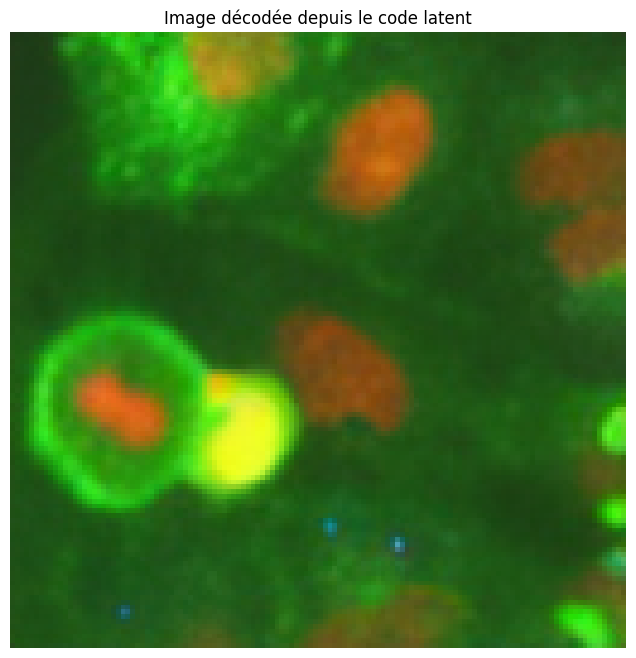

In [72]:
# decode
# Le VAE attend un batch, donc on ajoute une dimension batch
latent_code = photo1.unsqueeze(0)  # [1, 4, 16, 16]
print(f"latent_code shape avant décodage: {latent_code.shape}")

# Diviser par le scaling factor
latent_code = latent_code / vae.config.scaling_factor

# Décoder
orig = vae.decode(latent_code).sample

# viz
print("orig:", orig.shape, orig.dtype, orig.min().item(), orig.max().item())
orig = orig.clamp(-1, 1)  # S'assurer que les valeurs sont dans [-1, 1]
orig = (orig + 1) / 2  # Convertir de [-1, 1] à [0, 1]
orig = orig.clamp(0, 1)
orig *= 255

# Afficher l'image
plt.figure(figsize=(8, 8))
plt.imshow(orig[0].cpu().detach().numpy().transpose(1, 2, 0).astype(np.uint8))
plt.axis("off")
plt.title("Image décodée depuis le code latent")
plt.show()

## Save direct image-space downscaled images

In [29]:
DEFINITION = 128  # <= change the downscaling definition here (from 255*255 )

NUMBER_OF_CHANNELS = 3
transforms = Compose(
    transforms=[
        PILToTensor(),
        Resize(DEFINITION),
        ConvertImageDtype(torch.float32),  # converts to [0; 1]
        Normalize(mean=[0.5] * NUMBER_OF_CHANNELS, std=[0.5] * NUMBER_OF_CHANNELS),
    ]
)
ds = ImageFolder(
    "/projects/static2dynamic/datasets/biotine/3_channels_min_99_perc_normalized_rgb_stacks_png/patches_255",
    transform=transforms,
)
ds

Dataset ImageFolder
    Number of datapoints: 145472
    Root location: /projects/static2dynamic/datasets/biotine/3_channels_min_99_perc_normalized_rgb_stacks_png/patches_255
    StandardTransform
Transform: Compose(
               PILToTensor()
               Resize(size=128, interpolation=bilinear, max_size=None, antialias=True)
               ConvertImageDtype()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )

In [30]:
dl = DataLoader(ds, batch_size=2048, shuffle=False, num_workers=16, prefetch_factor=4)

In [33]:
base_save_dir = Path(
    f"/projects/static2dynamic/Gravier/datasets/biotine/downscaled_images_{DEFINITION}"
)
if base_save_dir.exists():
    print(f"Warning: '{base_save_dir}' already exists")
    print(f"Contents: {list(base_save_dir.iterdir())}")
else:
    base_save_dir.mkdir()
    print(f"Created directory: {base_save_dir}")

Created directory: /projects/static2dynamic/Gravier/datasets/biotine/downscaled_images_128


In [36]:
all_files = {}

for batch in tqdm.tqdm(iter(dl), total=len(dl)):
    img: Tensor = batch[0]
    times: Tensor = batch[1]

    # save downscaled images
    for img_idx, t in enumerate(times):
        time_label = idx_to_class[t.item()]
        if time_label not in all_files:
            all_files[time_label] = []
        this_img = img[img_idx]
        assert this_img.shape == (NUMBER_OF_CHANNELS, DEFINITION, DEFINITION), (
            f"Unexpected shape: {this_img.shape}"
        )
        all_files[time_label].append(this_img)

  0%|          | 0/72 [00:00<?, ?it/s]

In [37]:
print(f"Saving in {base_save_dir}:")

for k, v in all_files.items():
    all_files[k] = torch.stack(v)
    print(f"{k}: {all_files[k].shape}")

    torch.save(all_files[k], base_save_dir / f"time_{k}.pt")

Saving in /projects/static2dynamic/Gravier/datasets/biotine/downscaled_images_128:
1: torch.Size([7680, 3, 128, 128])
10: torch.Size([7616, 3, 128, 128])
11: torch.Size([7680, 3, 128, 128])
12: torch.Size([7616, 3, 128, 128])
13: torch.Size([7616, 3, 128, 128])
14: torch.Size([7680, 3, 128, 128])
15: torch.Size([7680, 3, 128, 128])
16: torch.Size([7680, 3, 128, 128])
17: torch.Size([7680, 3, 128, 128])
18: torch.Size([7680, 3, 128, 128])
19: torch.Size([7680, 3, 128, 128])
2: torch.Size([7680, 3, 128, 128])
3: torch.Size([7616, 3, 128, 128])
4: torch.Size([7680, 3, 128, 128])
5: torch.Size([7616, 3, 128, 128])
6: torch.Size([7680, 3, 128, 128])
7: torch.Size([7680, 3, 128, 128])
8: torch.Size([7616, 3, 128, 128])
9: torch.Size([7616, 3, 128, 128])


# Import Dataset

In [78]:
base_dir = Path("/projects/static2dynamic/datasets/biotine/downscaled_images_64")

In [79]:
for file_path in base_dir.glob("*.pt"):
    # Extract the number between "_" and "."
    key = file_path.stem.split("_")[1]
    # Load the tensor and move to device
    tensor = torch.load(file_path).to(device)
    # Store in dictionary
    if "tensors_dict" not in locals():
        tensors_dict = {}
    tensors_dict[key] = tensor

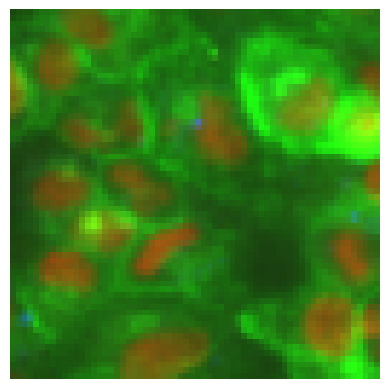

# IMPORT TRAJECTORY

In [23]:
traj_tensor = batch['generated']

In [7]:
del traj_tensor

NameError: name 'traj_tensor' is not defined

In [ ]:
base_dir = Path("/projects/static2dynamic/Gravier/schron/experiments_debug")
device = "cpu"
experiment_name = "biotine_7d_unet_image128_02"
direction_to_sample = "forward"
epoch = 2
# Construction du chemin du fichier
traj_filename = f"traj_iter_{epoch:04d}_direction_{direction_to_sample}.pt"
traj_path = base_dir / experiment_name / "trajectories_tensor" / traj_filename

# Charger le tensor sur le device
traj_tensor = torch.load(traj_path, map_location=device)


In [24]:
print(f"traj_tensor original shape: {traj_tensor.shape}")
print(f"traj_tensor dtype: {traj_tensor.dtype}")
print(f"Expected shape should be: (num_steps, num_samples, latent_dim)")
print(f"Where latent_dim = 4 * 16 * 16 = {4 * 16 * 16}")
print(f"traj filename : {traj_filename}")
print(f"traj path : {traj_path}")

traj_tensor original shape: torch.Size([602, 20, 3, 128, 128])
traj_tensor dtype: torch.float32
Expected shape should be: (num_steps, num_samples, latent_dim)
Where latent_dim = 4 * 16 * 16 = 1024


NameError: name 'traj_filename' is not defined

In [14]:
traj_tensor_reshaped = traj_tensor

In [26]:
# Le tensor a la forme (num_steps, num_samples, 4*16*16)
# On veut le transformer en (num_samples, num_steps, 4, 16, 16)
print(f"Avant reshape: {traj_tensor.shape}")

# Reshape pour récupérer les dimensions spatiales des codes latents
traj_tensor_reshaped = traj_tensor.view(
    traj_tensor.shape[0], traj_tensor.shape[1], 3, 128 , 128
)
print(f"Après premier reshape: {traj_tensor_reshaped.shape}")

# Permuter pour avoir (num_samples, num_steps, channels, height, width)
traj_tensor_reshaped = traj_tensor_reshaped.permute(1, 0, 2, 3, 4)
print(f"Après permutation: {traj_tensor_reshaped.shape}")
print(
    f"Format: (num_samples={traj_tensor_reshaped.shape[0]}, num_steps={traj_tensor_reshaped.shape[1]}, channels={traj_tensor_reshaped.shape[2]}, height={traj_tensor_reshaped.shape[3]}, width={traj_tensor_reshaped.shape[4]})"
)

Avant reshape: torch.Size([602, 20, 3, 128, 128])
Après premier reshape: torch.Size([602, 20, 3, 128, 128])
Après permutation: torch.Size([20, 602, 3, 128, 128])
Format: (num_samples=20, num_steps=602, channels=3, height=128, width=128)


In [27]:
# Sélectionner le premier échantillon au premier pas de temps
# Format attendu: [channels, height, width] = [4, 16, 16]
photo1 = traj_tensor_reshaped[0, 0]  # [4, 16, 16]
print(f"photo1 shape: {photo1.shape}")
print(f"photo1 dtype: {photo1.dtype}")
print(f"photo1 min/max: {photo1.min().item():.4f} / {photo1.max().item():.4f}")



photo1 shape: torch.Size([3, 128, 128])
photo1 dtype: torch.float32
photo1 min/max: -0.8980 / 1.0000


In [28]:
photo1[0][0][0]

tensor(-0.6941)

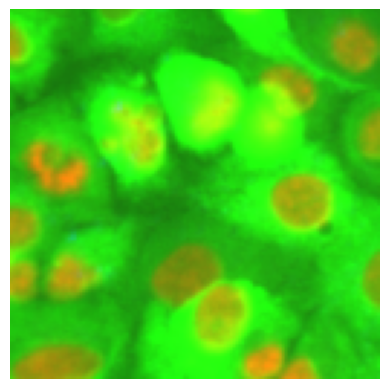

In [29]:
img = photo1
img_disp = (img + 1) / 2  # Si normalisé [-1,1] → [0,1]
img_disp = img_disp.clamp(0, 1)
plt.imshow(img_disp.permute(1, 2, 0).cpu().numpy())
plt.axis("off")
plt.show()

In [30]:
photo1.shape


torch.Size([3, 128, 128])

# Création vidéo

Création d'une vidéo à partir d'une trajectoire complète (1901 steps).
- 100 steps = 1 seconde
- 1901 steps ≈ 19 secondes de vidéo

In [31]:
# Imports pour la création vidéo
import matplotlib.pyplot as plt
import torch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import os
from torch import Tensor
from scipy.stats import gaussian_kde
from matplotlib import animation, cm


from typing import List
from matplotlib.animation import FFMpegWriter
from matplotlib import cm

In [32]:
def create_video_from_trajectory_matplotlib(
    trajectory_tensor, sample_idx, output_path, fps=100, decode=False
):
    """
    Crée une vidéo à partir d'une trajectoire en utilisant matplotlib.

    Args:
        trajectory_tensor: 
            - Si decode=True: Tensor (num_samples, num_steps, 4, 16, 16) (latents VAE)
            - Si decode=False: Tensor (num_samples, num_steps, 3, 128, 128) (images déjà décodées)
        sample_idx: Index de l'échantillon à utiliser
        output_path: Chemin de sortie pour la vidéo
        fps: Images par seconde (100 steps = 1s donc fps=100)
        decode: bool, True si on doit décoder avec le VAE, False si déjà décodé
    """
    print(f"   Création vidéo matplotlib pour l'échantillon {sample_idx}")
    print(f"   - Trajectoire: {trajectory_tensor.shape[1]} steps")
    print(f"   - FPS: {fps} ({fps} steps = 1 seconde)")
    print(f"   - Durée: {trajectory_tensor.shape[1] / fps:.1f} secondes")

    # Sélectionner la trajectoire
    single_trajectory = trajectory_tensor[sample_idx]  
    print(f"   - Shape trajectoire sélectionnée: {single_trajectory.shape}")

    all_images = []

    if decode:
        print(f"   - Décodage des {single_trajectory.shape[0]} frames...")
        for step_idx in tqdm.tqdm(range(single_trajectory.shape[0]), desc="Décodage frames"):
            latent_code = single_trajectory[step_idx]  # (4, 16, 16)
            latent_batch = latent_code.unsqueeze(0) / vae.config.scaling_factor

            with torch.no_grad():
                decoded = vae.decode(latent_batch).sample  # (1, 3, 128, 128)

            img = decoded[0].clamp(-1, 1)
            img = (img + 1) / 2  # [-1,1] -> [0,1]
            img = img.clamp(0, 1)

            img_np = img.cpu().numpy().transpose(1, 2, 0)  # (128, 128, 3)
            all_images.append(img_np)
    else:
        print(f"   - Utilisation directe des frames (pas de décodage).")
        for step_idx in range(single_trajectory.shape[0]):
            img = single_trajectory[step_idx]  # (3, 128, 128)
            img = (img +1)/2
            img = img.clamp(0, 1)  # sécurité si tensor déjà normalisé
            img_np = img.cpu().numpy().transpose(1, 2, 0)  # (128, 128, 3)
            all_images.append(img_np)

    print(f"   - Création de l'animation...")

    # Création animation matplotlib
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, 128)
    ax.set_ylim(0, 128)
    ax.axis("off")

    im = ax.imshow(all_images[0], animated=True)

    def animate(frame):
        im.set_array(all_images[frame])
        ax.set_title(f"Step {frame}/{len(all_images) - 1} - Time: {frame / fps:.2f}s")
        return [im]

    anim = animation.FuncAnimation(
        fig,
        animate,
        frames=len(all_images),
        interval=1000 / fps,
        blit=True,
        repeat=True,
    )

    # Sauvegarde vidéo
    print(f"   - Sauvegarde en cours...")
    writer = FFMpegWriter(fps=fps, metadata=dict(artist="VAE Trajectory"), bitrate=1800)
    anim.save(output_path, writer=writer)

    plt.close(fig)
    print(f"Vidéo sauvegardée: {output_path}")
    return output_path


In [38]:
# Paramètres pour la vidéo
sample_to_video = 5  # Échantillon à utiliser (0-999)
fps = 33  # 100 steps = 1 seconde

# Créer le répertoire de sortie à partir des variables existantes
output_dir = base_dir / experiment_name / "video"
output_dir.mkdir(exist_ok=True)

# Nom du fichier vidéo
video_filename = f"trajectory_sample_epoch_{epoch}_sample_{sample_to_video}_direction_{direction_to_sample}.mp4"
video_path = output_dir / video_filename

print(f" Configuration vidéo:")
print(f"   - Échantillon: {sample_to_video}")
print(f"   - Époque: {epoch}")
print(f"   - Direction: {direction_to_sample}")
print(f"   - FPS: {fps}")
print(f"   - Fichier: {video_filename}")

 Configuration vidéo:
   - Échantillon: 5
   - Époque: 2
   - Direction: forward
   - FPS: 33
   - Fichier: trajectory_sample_epoch_2_sample_5_direction_forward.mp4


In [39]:
# Créer la vidéo avec matplotlib
video_path_str = str(video_path)
created_video = create_video_from_trajectory_matplotlib(
    trajectory_tensor=traj_tensor_reshaped,
    sample_idx=sample_to_video,
    output_path=video_path_str,
    fps=fps,
)

   Création vidéo matplotlib pour l'échantillon 5
   - Trajectoire: 602 steps
   - FPS: 33 (33 steps = 1 seconde)
   - Durée: 18.2 secondes
   - Shape trajectoire sélectionnée: torch.Size([602, 3, 128, 128])
   - Utilisation directe des frames (pas de décodage).
   - Création de l'animation...
   - Sauvegarde en cours...
Vidéo sauvegardée: /projects/static2dynamic/Gravier/schron/experiments_debug/biotine_7d_unet_image128_02/video/trajectory_sample_epoch_2_sample_5_direction_forward.mp4


In [40]:
# Fonction pour créer plusieurs vidéos avec matplotlib
def create_multiple_videos_matplotlib(
    trajectory_tensor, sample_indices, output_dir, fps=100, prefix="trajectory"
):
    """
    Crée plusieurs vidéos pour différents échantillons avec matplotlib.

    Args:
        trajectory_tensor: Tensor de forme (num_samples, num_steps, 4, 16, 16)
        sample_indices: Liste des indices d'échantillons à traiter
        output_dir: Répertoire de sortie
        fps: Images par seconde
        prefix: Préfixe pour les noms de fichiers
    """
    from pathlib import Path

    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)

    created_videos = []

    print(f"🎬 Création de {len(sample_indices)} vidéos...")

    for i, idx in enumerate(sample_indices):
        print(f"\n📹 Vidéo {i + 1}/{len(sample_indices)} - Échantillon {idx}")

        video_filename = f"{prefix}_sample_{idx:03d}.mp4"
        video_path = output_dir / video_filename

        try:
            created_path = create_video_from_trajectory_matplotlib(
                trajectory_tensor=trajectory_tensor,
                sample_idx=idx,
                output_path=str(video_path),
                fps=fps,
            )
            created_videos.append(created_path)
            print(f"✅ Vidéo {idx} créée avec succès")
        except Exception as e:
            print(f"❌ Erreur pour l'échantillon {idx}: {e}")

    print(f"\n🎉 Terminé! {len(created_videos)}/{len(sample_indices)} vidéos créées")
    return created_videos

sample_list = [i for i in range(10)]
videos = create_multiple_videos_matplotlib(traj_tensor_reshaped, sample_list, "./videos2", fps=100)

🎬 Création de 10 vidéos...

📹 Vidéo 1/10 - Échantillon 0
   Création vidéo matplotlib pour l'échantillon 0
   - Trajectoire: 602 steps
   - FPS: 100 (100 steps = 1 seconde)
   - Durée: 6.0 secondes
   - Shape trajectoire sélectionnée: torch.Size([602, 3, 128, 128])
   - Utilisation directe des frames (pas de décodage).
   - Création de l'animation...
   - Sauvegarde en cours...
Vidéo sauvegardée: videos2/trajectory_sample_000.mp4
✅ Vidéo 0 créée avec succès

📹 Vidéo 2/10 - Échantillon 1
   Création vidéo matplotlib pour l'échantillon 1
   - Trajectoire: 602 steps
   - FPS: 100 (100 steps = 1 seconde)
   - Durée: 6.0 secondes
   - Shape trajectoire sélectionnée: torch.Size([602, 3, 128, 128])
   - Utilisation directe des frames (pas de décodage).
   - Création de l'animation...
   - Sauvegarde en cours...
Vidéo sauvegardée: videos2/trajectory_sample_001.mp4
✅ Vidéo 1 créée avec succès

📹 Vidéo 3/10 - Échantillon 2
   Création vidéo matplotlib pour l'échantillon 2
   - Trajectoire: 602 s

In [43]:
batch['generated'].shape

torch.Size([602, 20, 3, 128, 128])

# PCA and trajectoire

In [ ]:
from sklearn.decomposition import PCA
import torch


print(f"Préparation PCA sur {len(tensors_dict)} tensors")
print("=" * 50)

# Concaténer tous les tensors pour ajuster la PCA
all_tensors_list = []
tensor_shapes = {}
tensor_sizes = {}

for key, tensor in tensors_dict.items():
    # Sauvegarder la forme originale
    tensor_shapes[key] = tensor.shape

    # Aplatir le tensor (samples, features)
    tensor_flat = tensor.view(tensor.shape[0], -1)  # (n_samples, 4*16*16)
    tensor_sizes[key] = tensor_flat.shape[0]

    print(f"Temps {key}: {tensor.shape} → {tensor_flat.shape}")
    all_tensors_list.append(tensor_flat.cpu().numpy())

# Concaténer tous les échantillons de tous les temps
all_data = np.concatenate(all_tensors_list, axis=0)
print(f"\nDonnées totales pour PCA: {all_data.shape}")
print(f"   - {all_data.shape[0]} échantillons totaux")
print(f"   - {all_data.shape[1]} features (4×16×16 = {4 * 16 * 16})")

# Ajuster la PCA sur toutes les données
print(f"\nAjustement PCA en {100} dimensions...")
pca_operator = PCA(n_components=100, random_state=42)
pca_operator.fit(all_data)

print(f"PCA ajustée!")
print(
    f"   - Variance expliquée totale: {pca_operator.explained_variance_ratio_.sum():.4f}"
)
print(
    f"   - Top 10 composantes: {pca_operator.explained_variance_ratio_[:10].sum():.4f}"
)
print(f"   - Variance des 10 premières: {pca_operator.explained_variance_ratio_[:10]}")

# Appliquer la PCA à chaque tensor individuellement
tensors_dict_pca = {}
start_idx = 0

for key in sorted(tensors_dict.keys(), key=int):
    tensor = tensors_dict[key]
    n_samples = tensor_sizes[key]

    # Extraire les données correspondantes
    tensor_flat = tensor.view(tensor.shape[0], -1).cpu().numpy()

    # Appliquer la transformation PCA
    tensor_pca = pca_operator.transform(tensor_flat)

    # Convertir en tensor et remettre sur device
    tensor_pca_torch = torch.from_numpy(tensor_pca).float().to(device)

    # Stocker dans le nouveau dictionnaire
    tensors_dict_pca[key] = tensor_pca_torch

    print(f"Temps {key}: {tensor.shape} → {tensor_pca_torch.shape}")

print(f"\nRÉSUMÉ:")
print(f"   - Opérateur PCA conservé dans 'pca_operator'")
print(f"   - Nouveau dictionnaire 'tensors_dict_pca' créé")
print(f"   - Dimensions: {tensor.shape} → (n_samples, 100)")
print(
    f"   - Variance totale expliquée: {pca_operator.explained_variance_ratio_.sum():.1%}"
)
print(f"   - Clés disponibles: {sorted(tensors_dict_pca.keys())}")

# Vérification
print(f"\n Vérification:")
for key in sorted(tensors_dict_pca.keys())[:3]:  # Afficher seulement les 3 premiers
    original_shape = tensors_dict[key].shape
    pca_shape = tensors_dict_pca[key].shape
    print(f"   Temps {key}: {original_shape} → {pca_shape}")

NameError: name 'tensors_dict' is not defined

 Visualisation PCA 2D - Dimensions multiples
📊 Création des 4 visualisations:
   - Plot 1: Dimensions 0 vs 1
   - Plot 2: Dimensions 2 vs 3
   - Plot 3: Dimensions 4 vs 5
   - Plot 4: Dimensions 6 vs 7


 Visualisation PCA 2D - Dimensions multiples
📊 Création des 4 visualisations:
   - Plot 1: Dimensions 0 vs 1
   - Plot 2: Dimensions 2 vs 3
   - Plot 3: Dimensions 4 vs 5
   - Plot 4: Dimensions 6 vs 7


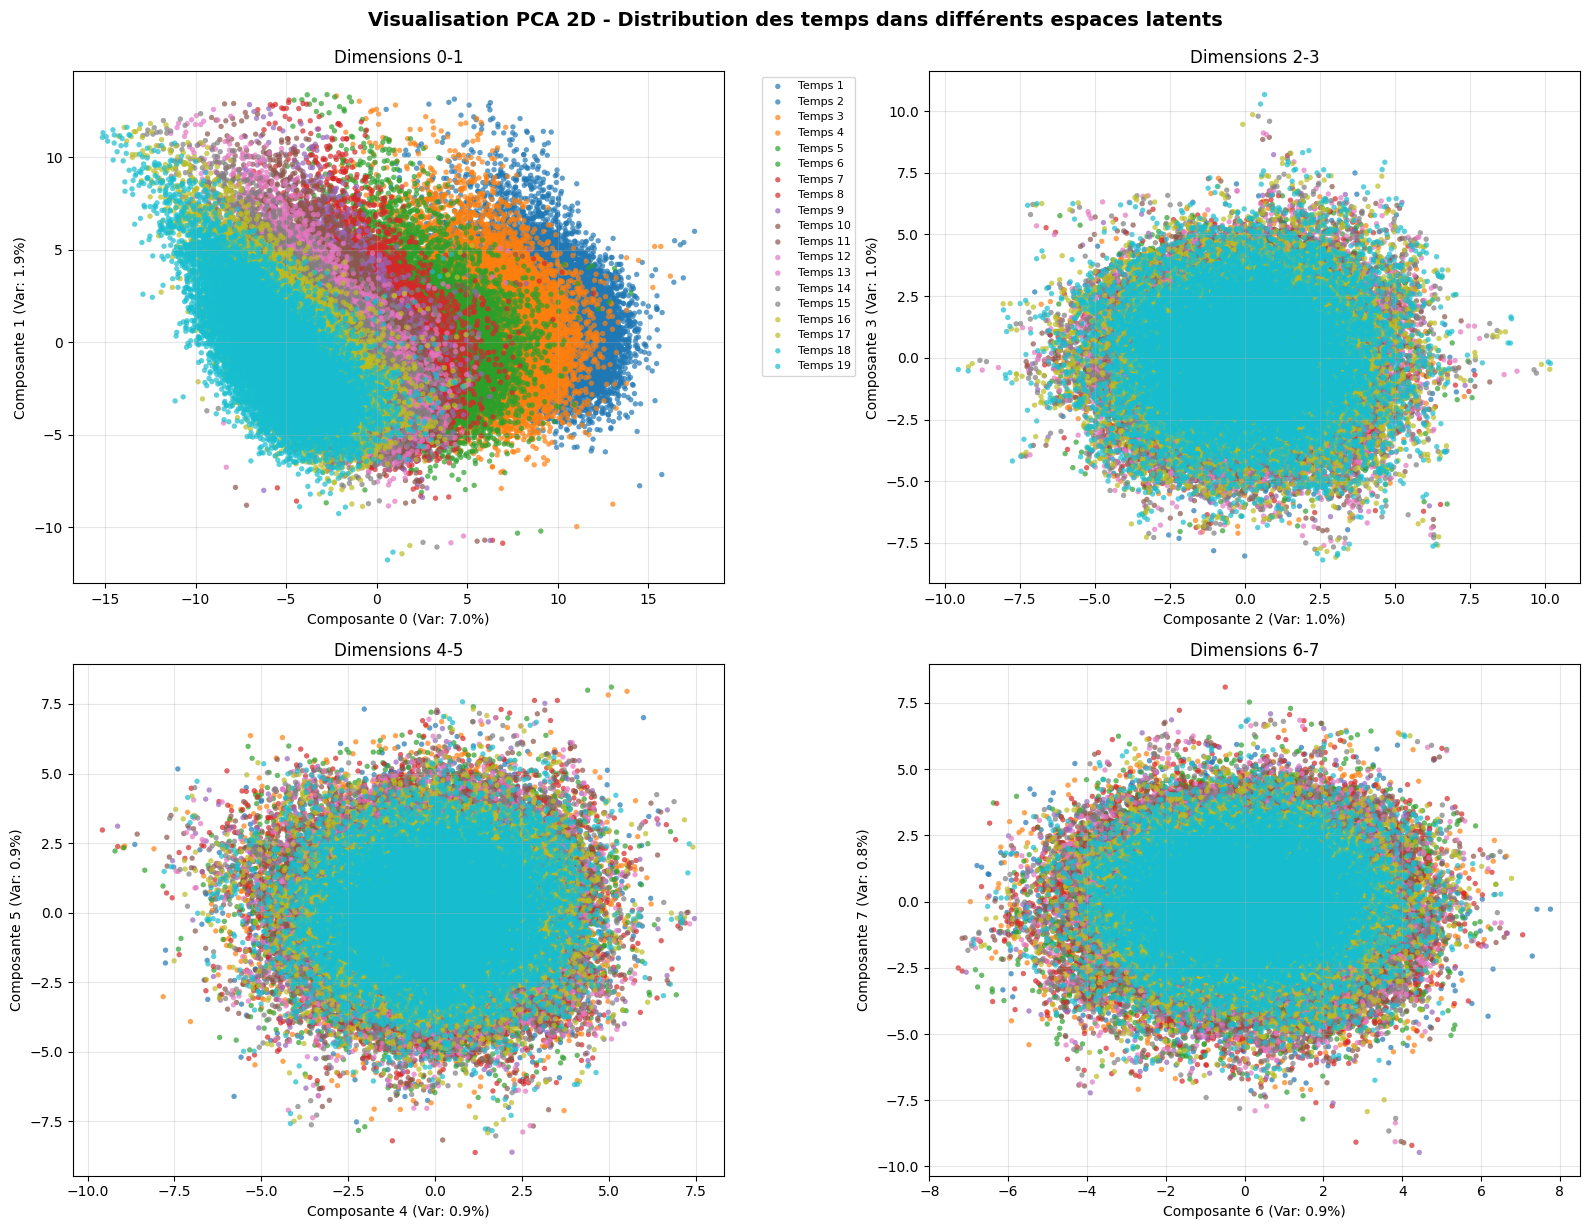

 Visualisation PCA 2D - Dimensions multiples
📊 Création des 4 visualisations:
   - Plot 1: Dimensions 0 vs 1
   - Plot 2: Dimensions 2 vs 3
   - Plot 3: Dimensions 4 vs 5
   - Plot 4: Dimensions 6 vs 7


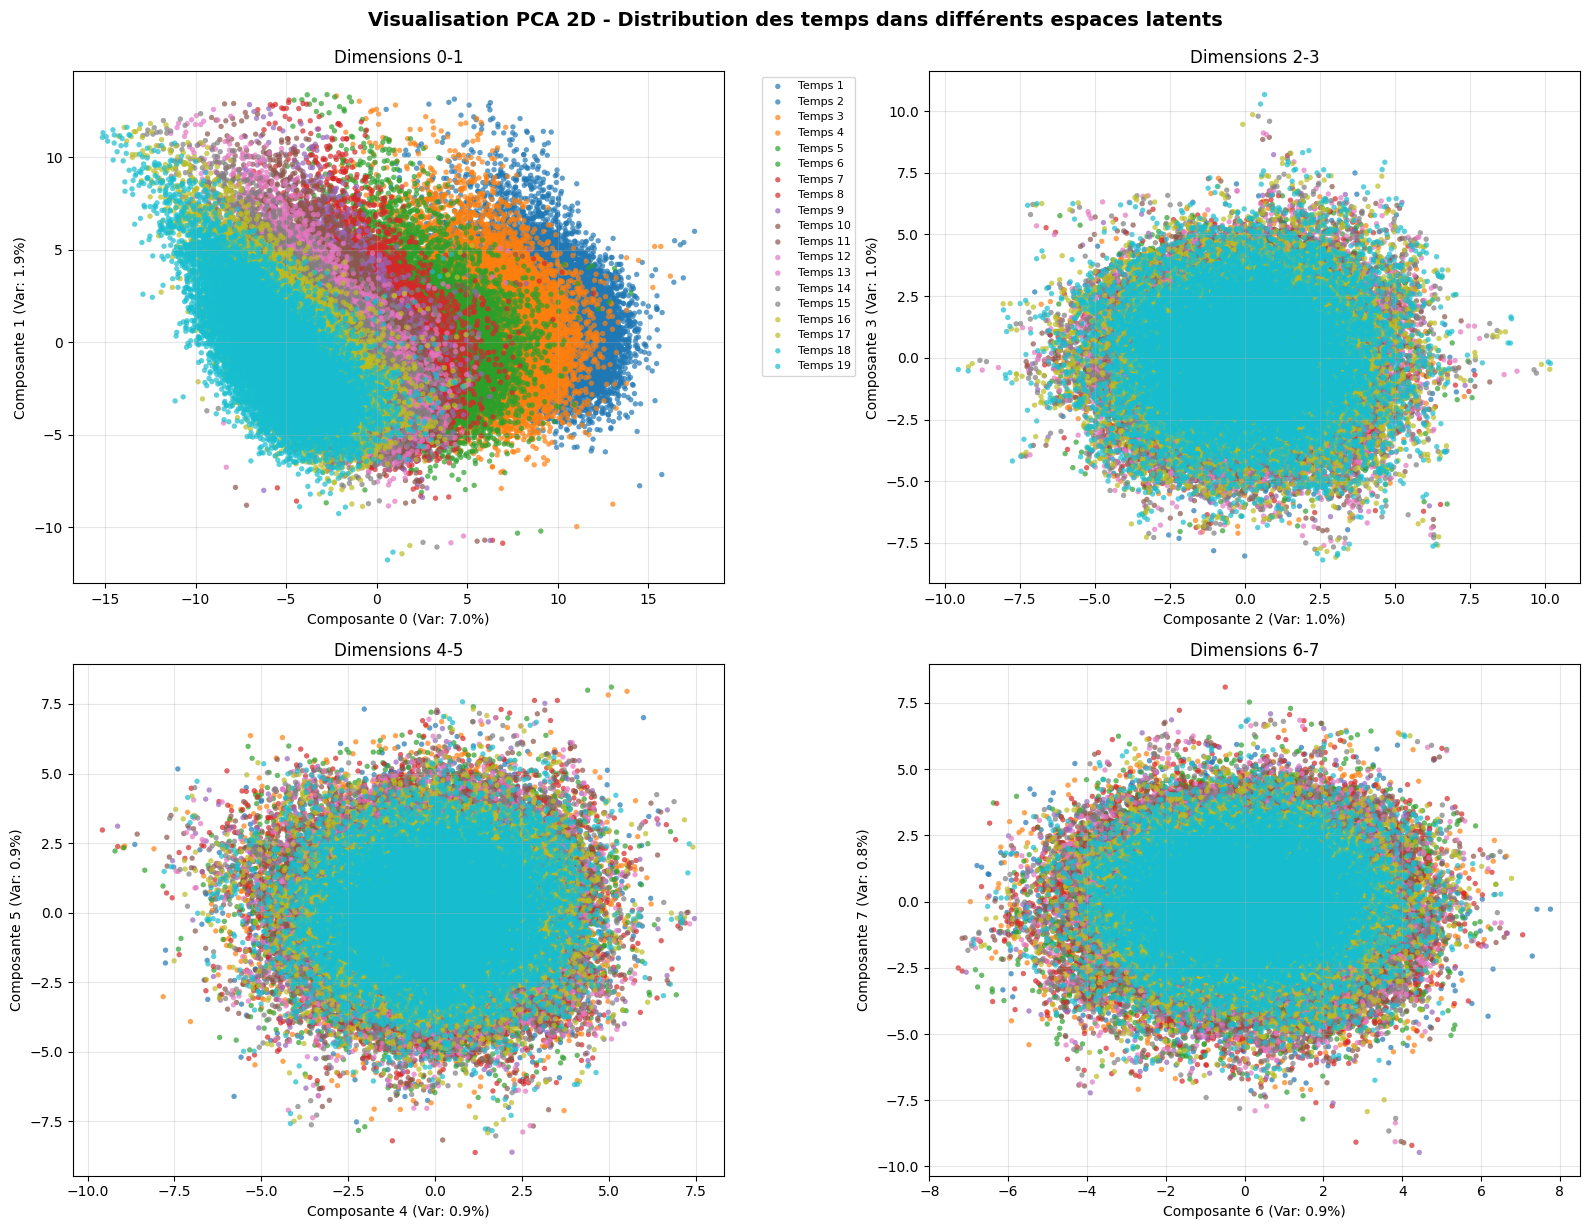


📈 Statistiques globales:
   Dimensions 0-1:
     - Dim 0: min=-15.145, max=17.543, std=5.117
     - Dim 1: min=-11.757, max=13.370, std=2.679
     - Variance expliquée: 8.9%
   Dimensions 2-3:
     - Dim 2: min=-9.543, max=10.191, std=1.941
     - Dim 3: min=-8.192, max=10.670, std=1.890
     - Variance expliquée: 2.0%
   Dimensions 4-5:
     - Dim 4: min=-9.575, max=7.469, std=1.810
     - Dim 5: min=-8.621, max=8.106, std=1.806
     - Variance expliquée: 1.7%
   Dimensions 6-7:
     - Dim 6: min=-7.266, max=7.760, std=1.791
     - Dim 7: min=-9.472, max=8.099, std=1.775
     - Variance expliquée: 1.7%

🎯 Variance totale expliquée (8 premières composantes): 14.3%
🔍 Détail par composante: [0.06990843 0.01915761 0.01005938 0.00953541 0.00875013 0.00870731
 0.00856571 0.00840905]


In [ ]:
# Visualisation 2D des données PCA - Dimensions multiples
print(" Visualisation PCA 2D - Dimensions multiples")
print("=" * 50)

# Créer la figure avec subplots 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()  # Pour un accès plus facile

# Définir une palette de couleurs pour chaque temps
import matplotlib.cm as cm

sorted_keys = sorted(tensors_dict_pca.keys(), key=int)
n_times = len(sorted_keys)
colors = cm.tab10(np.linspace(0, 1, n_times))

# Définir les paires de dimensions à visualiser
dim_pairs = [(0, 1), (2, 3), (4, 5), (6, 7)]
pair_titles = ["Dimensions 0-1", "Dimensions 2-3", "Dimensions 4-5", "Dimensions 6-7"]

print(f"📊 Création des 4 visualisations:")

# Plot pour chaque paire de dimensions
for plot_idx, (dim_x, dim_y) in enumerate(dim_pairs):
    ax = axes[plot_idx]

    print(f"   - Plot {plot_idx + 1}: Dimensions {dim_x} vs {dim_y}")

    # Plot pour chaque temps
    for i, key in enumerate(sorted_keys):
        # Récupérer les données PCA pour ce temps
        pca_data = tensors_dict_pca[key].cpu().numpy()

        # Extraire les dimensions correspondantes
        dim_data_x = pca_data[:, dim_x]
        dim_data_y = pca_data[:, dim_y]

        # Plot avec une couleur spécifique
        ax.scatter(
            dim_data_x,
            dim_data_y,
            c=[colors[i]],
            label=f"Temps {key}",
            alpha=0.7,
            s=15,
            edgecolors="none",
        )

    # Configuration du subplot
    var_x = pca_operator.explained_variance_ratio_[dim_x]
    var_y = pca_operator.explained_variance_ratio_[dim_y]
    ax.set_xlabel(f"Composante {dim_x} (Var: {var_x:.1%})")
    ax.set_ylabel(f"Composante {dim_y} (Var: {var_y:.1%})")
    ax.set_title(pair_titles[plot_idx])
    ax.grid(True, alpha=0.3)

    # Ajouter la légende seulement pour le premier subplot
    if plot_idx == 0:
        ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

# Ajuster le layout
plt.tight_layout()
plt.suptitle(
    "Visualisation PCA 2D - Distribution des temps dans différents espaces latents",
    y=1.02,
    fontsize=14,
    fontweight="bold",
)
plt.show()

# Afficher les statistiques globales pour toutes les dimensions
print(f"\n📈 Statistiques globales:")
for dim_x, dim_y in dim_pairs:
    all_dim_x = np.concatenate(
        [tensors_dict_pca[key].cpu().numpy()[:, dim_x] for key in sorted_keys]
    )
    all_dim_y = np.concatenate(
        [tensors_dict_pca[key].cpu().numpy()[:, dim_y] for key in sorted_keys]
    )

    print(f"   Dimensions {dim_x}-{dim_y}:")
    print(
        f"     - Dim {dim_x}: min={all_dim_x.min():.3f}, max={all_dim_x.max():.3f}, std={all_dim_x.std():.3f}"
    )
    print(
        f"     - Dim {dim_y}: min={all_dim_y.min():.3f}, max={all_dim_y.max():.3f}, std={all_dim_y.std():.3f}"
    )
    print(
        f"     - Variance expliquée: {pca_operator.explained_variance_ratio_[dim_x] + pca_operator.explained_variance_ratio_[dim_y]:.1%}"
    )

print(
    f"\n🎯 Variance totale expliquée (8 premières composantes): {pca_operator.explained_variance_ratio_[:8].sum():.1%}"
)
print(f"🔍 Détail par composante: {pca_operator.explained_variance_ratio_[:8]}")

 Application PCA aux trajectoires
 Shape trajectoires originales: torch.Size([10, 602, 4, 16, 16])
Shape trajectoires reshapées: torch.Size([10, 602, 1024])
Shape trajectoires aplaties pour PCA: torch.Size([6020, 1024])
 Application PCA avec l'opérateur existant...
 Shape trajectoires PCA: (6020, 100)
 Shape trajectoires PCA reshapées: (10, 602, 100)
Création des visualisations...


 Application PCA aux trajectoires
 Shape trajectoires originales: torch.Size([10, 602, 4, 16, 16])
Shape trajectoires reshapées: torch.Size([10, 602, 1024])
Shape trajectoires aplaties pour PCA: torch.Size([6020, 1024])
 Application PCA avec l'opérateur existant...
 Shape trajectoires PCA: (6020, 100)
 Shape trajectoires PCA reshapées: (10, 602, 100)
Création des visualisations...


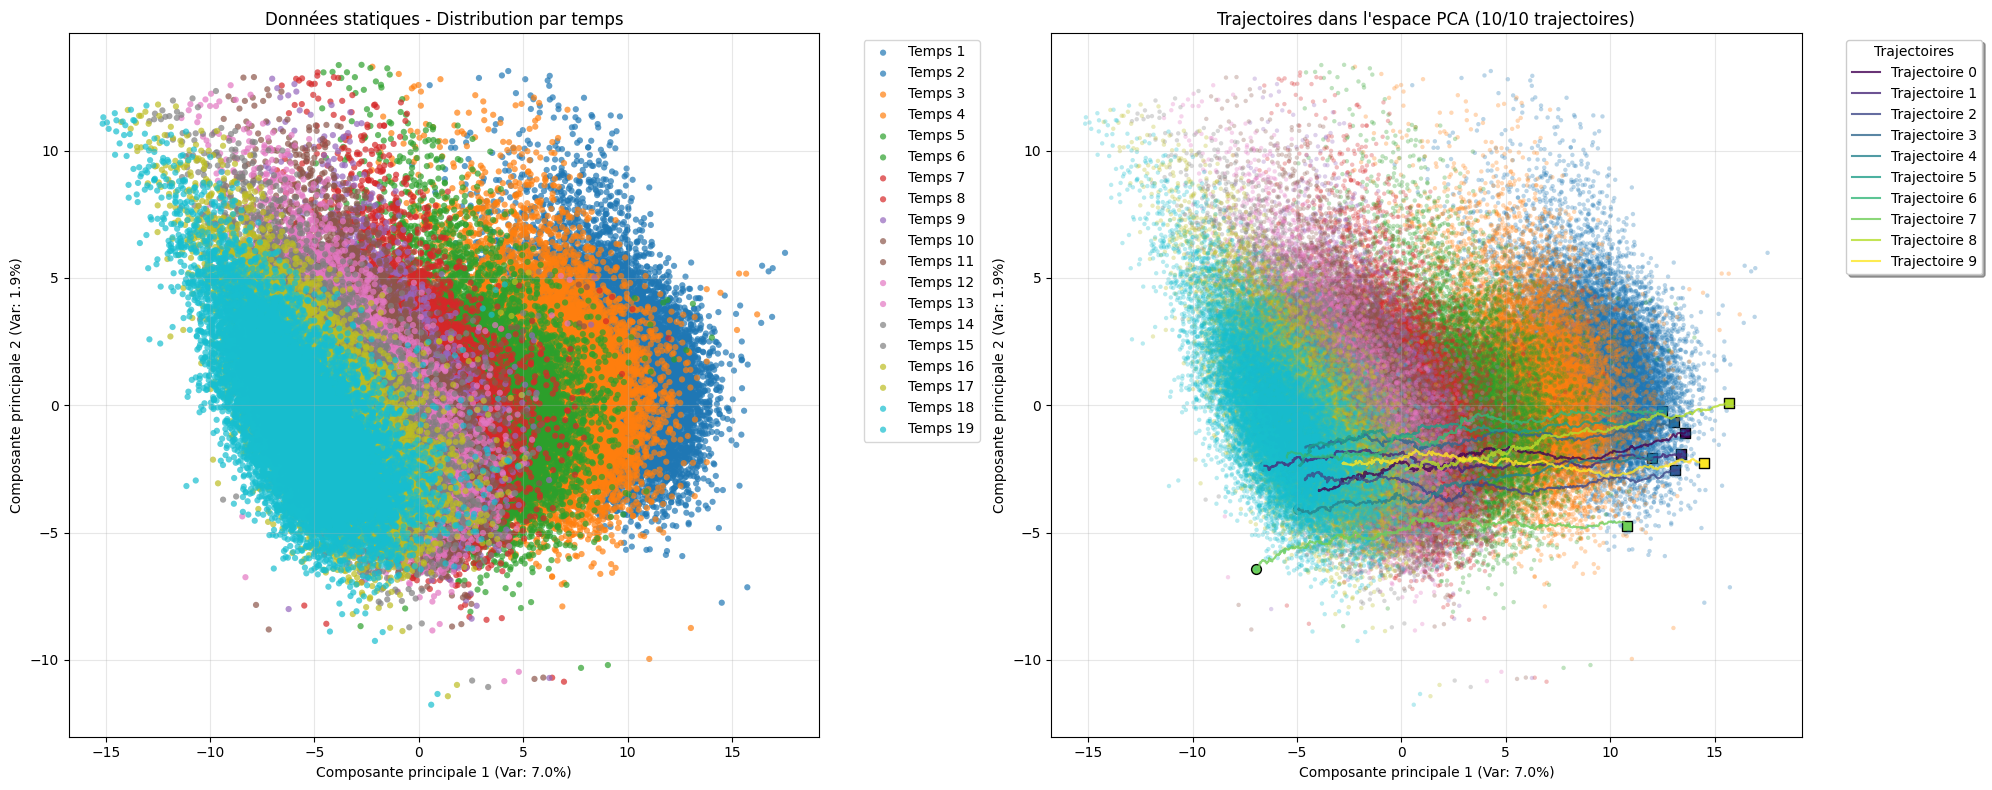


 Statistiques des trajectoires:
   - Nombre de trajectoires: 10
   - Nombre de steps par trajectoire: 602
   - Dimensions PCA: 100
   - Trajectoires visualisées: 10
   - Range Dim0 trajectoires: [-6.947, 15.713]
   - Range Dim1 trajectoires: [-6.435, 0.098]

 Trajectoires PCA sauvegardées dans 'traj_tensor_pca': torch.Size([10, 602, 100])

 Légende:
   - Cercles (o): Points de départ des trajectoires
   - Carrés (□): Points d'arrivée des trajectoires
   - Lignes: Chemin de la trajectoire
   - Points transparents: Données statiques de référence


In [ ]:
# Application de la PCA aux trajectoires et visualisation
print(" Application PCA aux trajectoires")
print("=" * 40)

# Vérifier que traj_tensor_reshaped existe
if "traj_tensor_reshaped" not in locals():
    print(
        " traj_tensor_reshaped n'existe pas. Veuillez d'abord charger et reshaper les trajectoires."
    )
else:
    print(f" Shape trajectoires originales: {traj_tensor_reshaped.shape}")

    # Reshape des trajectoires pour la PCA
    # De (num_traj, num_steps, 4, 16, 16) vers (num_traj, num_steps, 4*16*16)
    num_traj, num_steps = traj_tensor_reshaped.shape[0], traj_tensor_reshaped.shape[1]

    # D'abord aplatir en (num_traj, num_steps, -1)
    traj_reshaped_flat = traj_tensor_reshaped.reshape(
        num_traj, num_steps, -1
    )  # (num_traj, num_steps, 1024)
    print(f"Shape trajectoires reshapées: {traj_reshaped_flat.shape}")

    # Puis aplatir pour la PCA: (num_traj * num_steps, 1024)
    traj_flat = traj_reshaped_flat.reshape(num_traj * num_steps, -1)
    print(f"Shape trajectoires aplaties pour PCA: {traj_flat.shape}")

    # Appliquer la PCA (utiliser le même opérateur que pour les données statiques)
    print(f" Application PCA avec l'opérateur existant...")
    traj_pca = pca_operator.transform(traj_flat.cpu().numpy())
    print(f" Shape trajectoires PCA: {traj_pca.shape}")

    # Reshaper en (num_traj, num_steps, 100)
    traj_pca_reshaped = traj_pca.reshape(num_traj, num_steps, 100)
    print(f" Shape trajectoires PCA reshapées: {traj_pca_reshaped.shape}")

    # Créer la visualisation
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # Plot 1: Données statiques (référence)
    print(f"Création des visualisations...")
    sorted_keys = sorted(tensors_dict_pca.keys(), key=int)
    n_times = len(sorted_keys)
    colors = cm.tab10(np.linspace(0, 1, n_times))

    # Plot des données statiques
    for i, key in enumerate(sorted_keys):
        pca_data = tensors_dict_pca[key].cpu().numpy()
        dim0 = pca_data[:, 0]
        dim1 = pca_data[:, 1]
        ax1.scatter(
            dim0,
            dim1,
            c=[colors[i]],
            label=f"Temps {key}",
            alpha=0.7,
            s=20,
            edgecolors="none",
        )

    ax1.set_xlabel(
        f"Composante principale 1 (Var: {pca_operator.explained_variance_ratio_[0]:.1%})"
    )
    ax1.set_ylabel(
        f"Composante principale 2 (Var: {pca_operator.explained_variance_ratio_[1]:.1%})"
    )
    ax1.set_title("Données statiques - Distribution par temps")
    ax1.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax1.grid(True, alpha=0.3)

    # Plot 2: Trajectoires
    # Sélectionner quelques trajectoires pour la visualisation (éviter le surcharge)
    n_traj_to_show = min(10, num_traj)
    traj_indices = np.linspace(0, num_traj - 1, n_traj_to_show, dtype=int)

    # Colormap pour les trajectoires
    traj_colors = cm.viridis(np.linspace(0, 1, n_traj_to_show))

    for i, traj_idx in enumerate(traj_indices):
        # Extraire une trajectoire
        single_traj = traj_pca_reshaped[traj_idx]  # (num_steps, 100)

        # Dimensions 0 et 1
        traj_dim0 = single_traj[:, 0]
        traj_dim1 = single_traj[:, 1]

        # Plot de la trajectoire avec label pour la légende
        ax2.plot(
            traj_dim0,
            traj_dim1,
            color=traj_colors[i],
            alpha=0.8,
            linewidth=1.5,
            label=f"Trajectoire {traj_idx}",
        )

        # Marquer le début et la fin
        ax2.scatter(
            traj_dim0[0],
            traj_dim1[0],
            color=traj_colors[i],
            s=50,
            marker="o",
            edgecolors="black",
            linewidth=1,
            label="_nolegend_",
        )  # Début

        ax2.scatter(
            traj_dim0[-1],
            traj_dim1[-1],
            color=traj_colors[i],
            s=50,
            marker="s",
            edgecolors="black",
            linewidth=1,
            label="_nolegend_",
        )  # Fin

    # Ajouter les données statiques en arrière-plan pour référence
    for i, key in enumerate(sorted_keys):
        pca_data = tensors_dict_pca[key].cpu().numpy()
        dim0 = pca_data[:, 0]
        dim1 = pca_data[:, 1]
        ax2.scatter(
            dim0,
            dim1,
            c=[colors[i]],
            alpha=0.3,
            s=10,
            edgecolors="none",
            label="_nolegend_",
        )

    ax2.set_xlabel(
        f"Composante principale 1 (Var: {pca_operator.explained_variance_ratio_[0]:.1%})"
    )
    ax2.set_ylabel(
        f"Composante principale 2 (Var: {pca_operator.explained_variance_ratio_[1]:.1%})"
    )
    ax2.set_title(
        f"Trajectoires dans l'espace PCA ({n_traj_to_show}/{num_traj} trajectoires)"
    )

    # Créer une légende séparée pour les trajectoires
    ax2.legend(
        title="Trajectoires",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        frameon=True,
        fancybox=True,
        shadow=True,
    )
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Statistiques des trajectoires
    print(f"\n Statistiques des trajectoires:")
    print(f"   - Nombre de trajectoires: {num_traj}")
    print(f"   - Nombre de steps par trajectoire: {num_steps}")
    print(f"   - Dimensions PCA: {traj_pca_reshaped.shape[2]}")
    print(f"   - Trajectoires visualisées: {n_traj_to_show}")

    # Analyser les extrema des trajectoires
    all_traj_dim0 = traj_pca_reshaped[:, :, 0].flatten()
    all_traj_dim1 = traj_pca_reshaped[:, :, 1].flatten()
    print(
        f"   - Range Dim0 trajectoires: [{all_traj_dim0.min():.3f}, {all_traj_dim0.max():.3f}]"
    )
    print(
        f"   - Range Dim1 trajectoires: [{all_traj_dim1.min():.3f}, {all_traj_dim1.max():.3f}]"
    )

    # Sauvegarder les trajectoires PCA pour utilisation ultérieure
    traj_tensor_pca = torch.from_numpy(traj_pca_reshaped).float().to(device)
    print(
        f"\n Trajectoires PCA sauvegardées dans 'traj_tensor_pca': {traj_tensor_pca.shape}"
    )

    print(f"\n Légende:")
    print(f"   - Cercles (o): Points de départ des trajectoires")
    print(f"   - Carrés (□): Points d'arrivée des trajectoires")
    print(f"   - Lignes: Chemin de la trajectoire")
    print(f"   - Points transparents: Données statiques de référence")

torch.Size([7616, 100])

# Download MNIST Dataset

Téléchargement du dataset MNIST au format classique torchvision et organisation par classes dans le dossier schron/datasets/data/mnist

In [ ]:
import os
from torchvision.datasets import MNIST
from torchvision.transforms import (
    Compose,
    ToTensor,
    Normalize,
    Resize,
)
from pathlib import Path
import torch
from collections import defaultdict

# Configuration
MNIST_DATA_DIR = Path("/projects/static2dynamic/Gravier/schron/datasets/data/mnist")
MNIST_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Transformations MNIST classiques pour normaliser entre -1 et 1
# MNIST est en grayscale (1 channel), valeurs entre 0 et 1 après ToTensor()
# Pour passer de [0,1] à [-1,1]: (x - 0.5) / 0.5 = x * 2 - 1
# Équivalent: Normalize(mean=[0.5], std=[0.5])
transforms_mnist = Compose(
    [
        ToTensor(),  # Convertit PIL Image en tensor [0,1]
        # Resize à 32x32 (optionnel, MNIST natif est 28x28)
        Normalize(mean=[0.5], std=[0.5]),  # [0,1] -> [-1,1]
    ]
)

print(" Téléchargement du dataset MNIST...")
print(f"   - Répertoire de sortie: {MNIST_DATA_DIR}")
print(f"   - Transformations: ToTensor() + Resize(32) + Normalize(0.5, 0.5)")
print(f"   - Plage finale: [-1, 1]")

 Téléchargement du dataset MNIST...
   - Répertoire de sortie: /projects/static2dynamic/Gravier/schron/datasets/data/mnist
   - Transformations: ToTensor() + Resize(32) + Normalize(0.5, 0.5)
   - Plage finale: [-1, 1]


In [ ]:
# Télécharger MNIST train et test
print("🚂 Téléchargement MNIST Train...")
mnist_train = MNIST(
    root=str(MNIST_DATA_DIR), train=True, download=True, transform=transforms_mnist
)

print("🧪 Téléchargement MNIST Test...")
mnist_test = MNIST(
    root=str(MNIST_DATA_DIR), train=False, download=True, transform=transforms_mnist
)

print(f"✅ Téléchargement terminé!")
print(f"   - Train: {len(mnist_train)} échantillons")
print(f"   - Test: {len(mnist_test)} échantillons")
print(f"   - Classes: {mnist_train.classes}")
print(f"   - Nombre de classes: {len(mnist_train.classes)}")

🚂 Téléchargement MNIST Train...


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.10MB/s]

100%|██████████| 28.9k/28.9k [00:00<00:00, 365kB/s]

100%|██████████| 1.65M/1.65M [00:00<00:00, 2.56MB/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 2.37MB/s]

🧪 Téléchargement MNIST Test...
✅ Téléchargement terminé!
   - Train: 60000 échantillons
   - Test: 10000 échantillons
   - Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
   - Nombre de classes: 10


In [ ]:
# Organisation par classes (comme pour biotine)
print("📊 Organisation des données par classes...")

# Dictionnaire pour stocker les données par classe
data_by_class = defaultdict(list)

# Traiter le dataset train
print("   - Traitement du dataset train...")
for idx, (image, label) in enumerate(tqdm.tqdm(mnist_train, desc="Train")):
    data_by_class[label].append(image)

# Traiter le dataset test
print("   - Traitement du dataset test...")
for idx, (image, label) in enumerate(tqdm.tqdm(mnist_test, desc="Test")):
    data_by_class[label].append(image)

# Convertir en tensors et sauvegarder
print("💾 Sauvegarde par classes...")
for class_idx in range(10):  # MNIST a 10 classes (0-9)
    if class_idx in data_by_class:
        # Stack tous les tensors de cette classe
        class_tensor = torch.stack(data_by_class[class_idx])

        # Nom du fichier
        filename = f"class_{class_idx}.pt"
        filepath = MNIST_DATA_DIR / filename

        # Sauvegarder
        torch.save(class_tensor, filepath)

        print(f"   ✅ Classe {class_idx}: {class_tensor.shape} → {filename}")

        # Vérification des valeurs
        min_val = class_tensor.min().item()
        max_val = class_tensor.max().item()
        print(f"      Range: [{min_val:.3f}, {max_val:.3f}]")

print(f"\n🎉 Sauvegarde terminée!")
print(f"   - Répertoire: {MNIST_DATA_DIR}")
print(f"   - Format: class_{{0-9}}.pt")
print(f"   - Plage de valeurs: [-1, 1]")
print(f"   - Dimensions: (n_samples, 1, 32, 32)")

📊 Organisation des données par classes...
   - Traitement du dataset train...


Train:   0%|          | 0/60000 [00:00<?, ?it/s]

   - Traitement du dataset test...


Test:   0%|          | 0/10000 [00:00<?, ?it/s]

💾 Sauvegarde par classes...
   ✅ Classe 0: torch.Size([6903, 1, 28, 28]) → class_0.pt
      Range: [-1.000, 1.000]
   ✅ Classe 1: torch.Size([7877, 1, 28, 28]) → class_1.pt
      Range: [-1.000, 1.000]
   ✅ Classe 2: torch.Size([6990, 1, 28, 28]) → class_2.pt
      Range: [-1.000, 1.000]
   ✅ Classe 3: torch.Size([7141, 1, 28, 28]) → class_3.pt
      Range: [-1.000, 1.000]
   ✅ Classe 4: torch.Size([6824, 1, 28, 28]) → class_4.pt
      Range: [-1.000, 1.000]
   ✅ Classe 5: torch.Size([6313, 1, 28, 28]) → class_5.pt
      Range: [-1.000, 1.000]
   ✅ Classe 2: torch.Size([6990, 1, 28, 28]) → class_2.pt
      Range: [-1.000, 1.000]
   ✅ Classe 3: torch.Size([7141, 1, 28, 28]) → class_3.pt
      Range: [-1.000, 1.000]
   ✅ Classe 4: torch.Size([6824, 1, 28, 28]) → class_4.pt
      Range: [-1.000, 1.000]
   ✅ Classe 5: torch.Size([6313, 1, 28, 28]) → class_5.pt
      Range: [-1.000, 1.000]
   ✅ Classe 6: torch.Size([6876, 1, 28, 28]) → class_6.pt
      Range: [-1.000, 1.000]
   ✅ Classe 7: 

🔍 Vérification des fichiers sauvegardés...
📁 Fichiers créés (10):
   - class_0.pt: torch.Size([6903, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_1.pt: torch.Size([7877, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_2.pt: torch.Size([6990, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_3.pt: torch.Size([7141, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_4.pt: torch.Size([6824, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_5.pt: torch.Size([6313, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_6.pt: torch.Size([6876, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_7.pt: torch.Size([7293, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_8.pt: torch.Size([6825, 1, 28, 28]), dtype=torch.float32
     Range: [-1.000, 1.000]
   - class_9.pt: torch.Size([6958, 1, 28, 28]), dtype=torch.float32
  

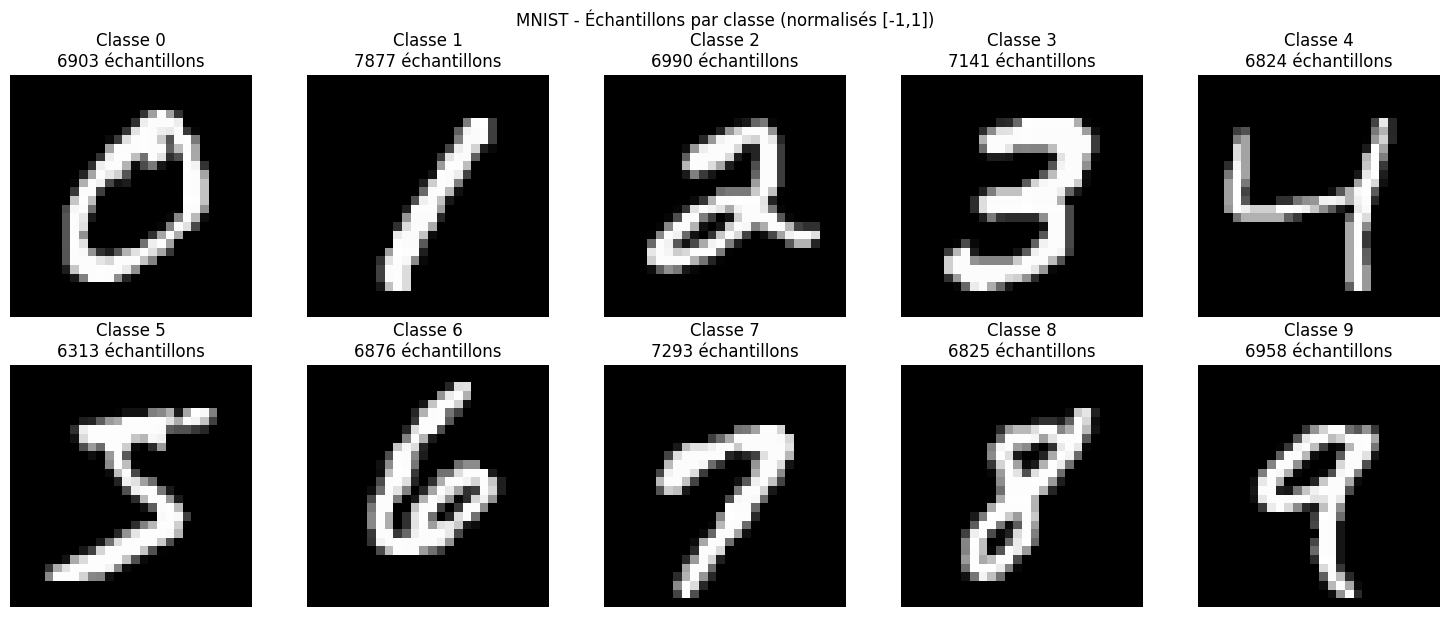


📊 Statistiques globales:
   - Total échantillons: 70000
   - Classes: 0-9 (10 classes)
   - Format des tensors: (n_samples, 1, 32, 32)
   - Type: torch.float32
   - Normalisation: [-1, 1]
   - Répertoire: /projects/static2dynamic/Gravier/schron/datasets/data/mnist


In [ ]:
# Vérification et visualisation
print("🔍 Vérification des fichiers sauvegardés...")

# Lister les fichiers créés
created_files = list(MNIST_DATA_DIR.glob("class_*.pt"))
created_files.sort()

print(f"📁 Fichiers créés ({len(created_files)}):")
for file_path in created_files:
    # Charger le tensor pour vérifier
    tensor = torch.load(file_path)
    print(f"   - {file_path.name}: {tensor.shape}, dtype={tensor.dtype}")
    print(f"     Range: [{tensor.min().item():.3f}, {tensor.max().item():.3f}]")

print(f"\n📈 Visualisation d'échantillons...")

# Créer une figure pour visualiser quelques échantillons de chaque classe
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for class_idx in range(10):
    # Charger les données de cette classe
    class_file = MNIST_DATA_DIR / f"class_{class_idx}.pt"
    if class_file.exists():
        class_data = torch.load(class_file)

        # Prendre le premier échantillon
        sample = class_data[0]  # (1, 32, 32)

        # Convertir de [-1,1] à [0,1] pour l'affichage
        sample_display = (sample + 1) / 2
        sample_display = sample_display.clamp(0, 1)

        # Afficher
        axes[class_idx].imshow(sample_display.squeeze(), cmap="gray")
        axes[class_idx].set_title(
            f"Classe {class_idx}\n{class_data.shape[0]} échantillons"
        )
        axes[class_idx].axis("off")

plt.tight_layout()
plt.suptitle("MNIST - Échantillons par classe (normalisés [-1,1])", y=1.02)
plt.show()

# Statistiques globales
total_samples = sum(torch.load(f).shape[0] for f in created_files)
print(f"\n📊 Statistiques globales:")
print(f"   - Total échantillons: {total_samples}")
print(f"   - Classes: 0-9 (10 classes)")
print(f"   - Format des tensors: (n_samples, 1, 32, 32)")
print(f"   - Type: {torch.load(created_files[0]).dtype}")
print(f"   - Normalisation: [-1, 1]")
print(f"   - Répertoire: {MNIST_DATA_DIR}")

In [2]:
device = "cuda"
# Imports pour la création vidéo
import matplotlib.pyplot as plt
import torch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import os
from torch import Tensor
from scipy.stats import gaussian_kde
from matplotlib import animation, cm


from typing import List
from matplotlib.animation import FFMpegWriter
from matplotlib import cm

In [4]:
import torch
from pathlib import Path

# === Config ===
experiment_dir = Path("/projects/static2dynamic/Gravier/schron/experiments_debug")
experiment_name = "biotine_7d_unet_image128_02"
direction_to_sample = "forward"
epoch = 14
device = "cpu"  # ou "cuda"

# === Construction du chemin ===
traj_filename = f"traj_iter_{epoch:04d}_direction_{direction_to_sample}.pt"
traj_dir = experiment_dir / experiment_name / "trajectories_tensor"
traj_path = traj_dir / traj_filename

print(f"📁 Chemin trajectoire: {traj_path}")

if traj_path.exists():
    print("✅ Fichier trouvé, chargement en cours...")
    traj_tensor = torch.load(traj_path, map_location=device)
    print(f"📊 Shape original: {traj_tensor.shape}")

    # Cas 1 : aplati (num_steps, num_samples, 784)
    if traj_tensor.ndim == 3:
        num_steps, num_samples, flattened_dim = traj_tensor.shape
        assert flattened_dim == 784, f"⚠️ attendu 784, trouvé {flattened_dim}"
        traj_tensor = traj_tensor.view(num_steps, num_samples, 1, 28, 28)

    # Cas 2 : déjà image (num_steps, num_samples, 1, 28, 28)
    elif traj_tensor.ndim == 5:
        num_steps, num_samples, c, h, w = traj_tensor.shape
        assert (c, h, w) == (1, 28, 28) or (3, 64, 64), f"⚠️ shape inattendue {(c, h, w)}"

    else:
        raise ValueError(f"⚠️ Tenseur MNIST inattendu ndim={traj_tensor.ndim}")

    # Permutation finale : (num_samples, num_steps, 1, 28, 28)
    traj_tensor_mnist_final = traj_tensor.permute(1, 0, 2, 3, 4)
    print(f"🎯 Shape final: {traj_tensor_mnist_final.shape}")

else:
    raise FileNotFoundError(f"❌ Fichier trajectoire non trouvé: {traj_path}")


📁 Chemin trajectoire: /projects/static2dynamic/Gravier/schron/experiments_debug/biotine_7d_unet_image128_02/trajectories_tensor/traj_iter_0014_direction_forward.pt
✅ Fichier trouvé, chargement en cours...
📊 Shape original: torch.Size([602, 10, 3, 128, 128])
🎯 Shape final: torch.Size([10, 602, 3, 128, 128])


In [5]:
# Fonction de visualisation pour les trajectoires MNIST
def visualize_mnist_trajectory(
    trajectory_tensor, sample_idx, num_steps_to_show=10, figsize=(15, 3)
):
    """
    Visualise une trajectoire MNIST (sans VAE).

    Args:
        trajectory_tensor: Tensor de forme (num_samples, num_steps, 1, 28, 28)
        sample_idx: Index de l'échantillon à visualiser
        num_steps_to_show: Nombre de steps à afficher
        figsize: Taille de la figure
    """
    if (
        "traj_tensor_mnist_final" not in locals()
        and "traj_tensor_mnist_final" not in globals()
    ):
        print(
            "❌ Trajectoires MNIST non chargées. Exécutez d'abord la cellule de chargement."
        )
        return

    # Récupérer la trajectoire pour cet échantillon
    single_traj = trajectory_tensor[sample_idx]  # (num_steps, 1, 28, 28)
    total_steps = single_traj.shape[0]

    # Sélectionner les steps à afficher (répartis uniformément)
    if num_steps_to_show > total_steps:
        step_indices = list(range(total_steps))
    else:
        step_indices = np.linspace(0, total_steps - 1, num_steps_to_show, dtype=int)

    print(f"🖼️  Visualisation trajectoire MNIST - Échantillon {sample_idx}")
    print(f"   - Steps sélectionnés: {step_indices}")
    print(f"   - Total steps: {total_steps}")

    # Créer la figure
    fig, axes = plt.subplots(1, len(step_indices), figsize=figsize)
    if len(step_indices) == 1:
        axes = [axes]

    for i, step_idx in enumerate(step_indices):
        # Récupérer l'image à ce step
        img = single_traj[step_idx, 0]  # (28, 28)

        # Convertir de [-1,1] à [0,1] pour l'affichage
        img_display = (img + 1) / 2
        img_display = img_display.clamp(0, 1)

        # Afficher
        axes[i].imshow(img_display.cpu().numpy(), cmap="gray")
        axes[i].set_title(f"Step {step_idx}\n({step_idx / total_steps:.1%})")
        axes[i].axis("off")

    plt.tight_layout()
    plt.suptitle(
        f"Trajectoire MNIST - Échantillon {sample_idx} ({len(step_indices)} steps)",
        y=1.05,
    )
    plt.show()

    # Statistiques
    min_val = single_traj.min().item()
    max_val = single_traj.max().item()
    mean_val = single_traj.mean().item()
    print(f"📊 Statistiques échantillon {sample_idx}:")
    print(f"   - Min: {min_val:.3f}, Max: {max_val:.3f}, Moyenne: {mean_val:.3f}")


# Fonction pour créer une vidéo MNIST (sans VAE)
def create_mnist_video(trajectory_tensor, sample_idx, output_path, fps=10):
    """
    Crée une vidéo à partir d'une trajectoire MNIST (sans VAE).

    Args:
        trajectory_tensor: Tensor de forme (num_samples, num_steps, 1, 28, 28)
        sample_idx: Index de l'échantillon à utiliser
        output_path: Chemin de sortie pour la vidéo
        fps: Images par seconde
    """
    print(f"🎬 Création vidéo MNIST pour l'échantillon {sample_idx}")

    # Sélectionner la trajectoire
    single_trajectory = trajectory_tensor[sample_idx]  # (num_steps, 1, 28, 28)
    num_steps = single_trajectory.shape[0]

    print(f"   - Nombre de frames: {num_steps}")
    print(f"   - FPS: {fps}")
    print(f"   - Durée: {num_steps / fps:.1f} secondes")

    # Préparer toutes les images
    all_images = []
    for step_idx in range(num_steps):
        # Récupérer l'image
        img = single_trajectory[step_idx, 0]  # (28, 28)

        # Convertir de [-1,1] à [0,1]
        img_display = (img + 1) / 2
        img_display = img_display.clamp(0, 1)

        # Convertir en numpy
        img_np = img_display.cpu().numpy()
        all_images.append(img_np)

    # Créer l'animation
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.axis("off")

    # Image initiale
    im = ax.imshow(all_images[0], cmap="gray", vmin=0, vmax=1, animated=True)

    def animate(frame):
        im.set_array(all_images[frame])
        ax.set_title(f"MNIST Trajectoire - Step {frame}/{len(all_images) - 1}")
        return [im]

    # Créer l'animation
    anim = animation.FuncAnimation(
        fig,
        animate,
        frames=len(all_images),
        interval=1000 / fps,
        blit=True,
        repeat=True,
    )

    # Sauvegarder
    print(f"💾 Sauvegarde en cours...")
    writer = FFMpegWriter(
        fps=fps, metadata=dict(artist="MNIST Trajectory"), bitrate=1800
    )
    anim.save(output_path, writer=writer)

    plt.close(fig)
    print(f"✅ Vidéo sauvegardée: {output_path}")
    return output_path

In [6]:
# Création vidéo MNIST interactive
print("🎬 Création de vidéo MNIST à partir des trajectoires")
print("=" * 50)

# Vérifier que les trajectoires sont chargées
if "traj_tensor_mnist_final" not in locals():
    print("❌ Erreur: Trajectoires MNIST non chargées!")
    print(
        "   Veuillez d'abord exécuter la cellule de chargement des trajectoires MNIST."
    )
else:
    # Afficher les informations sur les trajectoires disponibles
    num_samples, num_steps = (
        traj_tensor_mnist_final.shape[0],
        traj_tensor_mnist_final.shape[1],
    )
    print(f"📊 Trajectoires disponibles:")
    print(f"   - Nombre d'échantillons: {num_samples}")
    print(f"   - Nombre de steps par trajectoire: {num_steps}")
    print(f"   - Expérience: {experiment_name}")
    print(f"   - Époque: {epoch}")
    print(f"   - Direction: {direction_to_sample}")

    # Demander le numéro de trajectoire
    print(f"\n🎯 Sélection de la trajectoire:")
    sample_idx = int(
        input(f"Entrez le numéro de la trajectoire (0-{num_samples - 1}): ")
    )

    # Vérifier que le numéro est valide
    if 0 <= sample_idx < num_samples:
        print(f"✅ Trajectoire {sample_idx} sélectionnée")

        # Configuration vidéo
        fps = 20  # FPS pour MNIST (plus rapide que biotine)

        # Créer le répertoire de sortie
        video_output_dir = experiment_dir / experiment_name / "video"
        video_output_dir.mkdir(parents=True, exist_ok=True)

        # Nom du fichier vidéo
        video_filename = f"mnist_trajectory_sample_{sample_idx:03d}_epoch_{epoch:04d}_direction_{direction_to_sample}.mp4"
        video_path = video_output_dir / video_filename

        print(f"\n📹 Configuration vidéo:")
        print(f"   - Échantillon: {sample_idx}")
        print(f"   - FPS: {fps}")
        print(f"   - Durée estimée: {num_steps / fps:.1f} secondes")
        print(f"   - Fichier: {video_filename}")
        print(f"   - Répertoire: {video_output_dir}")

        # Créer la vidéo
        print(f"\n🎬 Création de la vidéo en cours...")
        try:
            created_video_path = create_mnist_video(
                trajectory_tensor=traj_tensor_mnist_final,
                sample_idx=sample_idx,
                output_path=str(video_path),
                fps=fps,
            )
            print(f"\n🎉 Vidéo créée avec succès!")
            print(f"   📁 Chemin: {created_video_path}")

            # Afficher quelques frames de la trajectoire
            print(f"\n🖼️  Aperçu de la trajectoire:")
            visualize_mnist_trajectory(
                trajectory_tensor=traj_tensor_mnist_final,
                sample_idx=sample_idx,
                num_steps_to_show=8,
                figsize=(16, 3),
            )

        except Exception as e:
            print(f"❌ Erreur lors de la création de la vidéo: {e}")
            import traceback

            traceback.print_exc()

    else:
        print(f"❌ Erreur: Numéro de trajectoire invalide!")
        print(f"   Le numéro doit être entre 0 et {num_samples - 1}")
        print(f"   Vous avez entré: {sample_idx}")

🎬 Création de vidéo MNIST à partir des trajectoires
📊 Trajectoires disponibles:
   - Nombre d'échantillons: 10
   - Nombre de steps par trajectoire: 602
   - Expérience: biotine_7d_unet_image128_02
   - Époque: 14
   - Direction: forward

🎯 Sélection de la trajectoire:


ValueError: invalid literal for int() with base 10: ''

In [ ]:
# Création de plusieurs vidéos MNIST en lot (optionnel)
print("🎬 Création de plusieurs vidéos MNIST en lot")
print("=" * 50)

if "traj_tensor_mnist_final" not in locals():
    print("❌ Trajectoires MNIST non chargées!")
else:
    num_samples = traj_tensor_mnist_final.shape[0]

    # Demander combien de vidéos créer
    print(f"📊 {num_samples} trajectoires disponibles")
    choice = input("Voulez-vous créer plusieurs vidéos? (y/n): ").lower().strip()

    if choice in ["y", "yes", "oui", "o"]:
        # Demander quelles trajectoires
        print("\nOptions:")
        print("1. Trajectoires spécifiques (ex: 0,5,10)")
        print("2. Plage de trajectoires (ex: 0-5)")
        print("3. Échantillonnage aléatoire (ex: 5 trajectoires aléatoires)")

        option = input("Choisissez une option (1/2/3): ").strip()

        sample_indices = []

        if option == "1":
            # Trajectoires spécifiques
            indices_str = input(
                f"Entrez les numéros séparés par des virgules (0-{num_samples - 1}): "
            )
            try:
                sample_indices = [int(x.strip()) for x in indices_str.split(",")]
                sample_indices = [
                    idx for idx in sample_indices if 0 <= idx < num_samples
                ]
            except:
                print("❌ Format invalide!")

        elif option == "2":
            # Plage
            range_str = input(f"Entrez la plage (ex: 0-5): ")
            try:
                start, end = map(int, range_str.split("-"))
                start = max(0, start)
                end = min(num_samples - 1, end)
                sample_indices = list(range(start, end + 1))
            except:
                print("❌ Format invalide!")

        elif option == "3":
            # Aléatoire
            try:
                num_random = int(
                    input(f"Combien de trajectoires aléatoires (max {num_samples}): ")
                )
                num_random = min(num_random, num_samples)
                import random

                sample_indices = random.sample(range(num_samples), num_random)
                sample_indices.sort()
            except:
                print("❌ Nombre invalide!")

        if sample_indices:
            print(f"\n🎯 Trajectoires sélectionnées: {sample_indices}")
            print(f"📹 Création de {len(sample_indices)} vidéos...")

            # Configuration
            fps = 20
            video_output_dir = experiment_dir / experiment_name / "video"
            video_output_dir.mkdir(parents=True, exist_ok=True)

            created_videos = []

            for i, sample_idx in enumerate(sample_indices):
                print(
                    f"\n📹 Vidéo {i + 1}/{len(sample_indices)} - Échantillon {sample_idx}"
                )

                # Nom du fichier
                video_filename = f"mnist_trajectory_sample_{sample_idx:03d}_epoch_{epoch:04d}_direction_{direction_to_sample}.mp4"
                video_path = video_output_dir / video_filename

                try:
                    created_path = create_mnist_video(
                        trajectory_tensor=traj_tensor_mnist_final,
                        sample_idx=sample_idx,
                        output_path=str(video_path),
                        fps=fps,
                    )
                    created_videos.append(created_path)
                    print(f"✅ Vidéo {sample_idx} créée")

                except Exception as e:
                    print(f"❌ Erreur pour l'échantillon {sample_idx}: {e}")

            print(
                f"\n🎉 Terminé! {len(created_videos)}/{len(sample_indices)} vidéos créées"
            )
            print(f"📁 Répertoire: {video_output_dir}")

            # Lister les vidéos créées
            if created_videos:
                print(f"\n📋 Vidéos créées:")
                for video_path in created_videos[-5:]:  # Afficher les 5 dernières
                    print(f"   - {Path(video_path).name}")
                if len(created_videos) > 5:
                    print(f"   ... et {len(created_videos) - 5} autres")
        else:
            print("❌ Aucune trajectoire sélectionnée!")
    else:
        print("👍 Pas de création de vidéos en lot.")

🎬 Création de plusieurs vidéos MNIST en lot
📊 10 trajectoires disponibles

Options:
1. Trajectoires spécifiques (ex: 0,5,10)
2. Plage de trajectoires (ex: 0-5)
3. Échantillonnage aléatoire (ex: 5 trajectoires aléatoires)

🎯 Trajectoires sélectionnées: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
📹 Création de 10 vidéos...

📹 Vidéo 1/10 - Échantillon 0
🎬 Création vidéo MNIST pour l'échantillon 0
   - Nombre de frames: 602
   - FPS: 20
   - Durée: 30.1 secondes
💾 Sauvegarde en cours...
✅ Vidéo sauvegardée: /projects/static2dynamic/Gravier/schron/experiments_debug/biotine_7d_unet_image128_02/video/mnist_trajectory_sample_000_epoch_0014_direction_forward.mp4
✅ Vidéo 0 créée

📹 Vidéo 2/10 - Échantillon 1
🎬 Création vidéo MNIST pour l'échantillon 1
   - Nombre de frames: 602
   - FPS: 20
   - Durée: 30.1 secondes
💾 Sauvegarde en cours...
❌ Erreur pour l'échantillon 1: Command '['ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '600x600', '-pix_fmt', 'rgba', '-framerate', '20', '-loglevel', 'error',

# Chargement et extraction de frames de vidéo

Fonction pour charger une vidéo et extraire des frames spécifiques par numéro d'image.

In [1]:
# Imports pour le traitement vidéo

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

In [ ]:
class VideoLoader:
    """
    Classe pour charger une vidéo et extraire des frames spécifiques.
    """

    def __init__(self, video_path):
        """
        Initialise le chargeur de vidéo.

        Args:
            video_path: Chemin vers le fichier vidéo
        """
        self.video_path = Path(video_path)
        if not self.video_path.exists():
            raise FileNotFoundError(f"Fichier vidéo non trouvé: {video_path}")

        # Ouvrir la vidéo avec OpenCV
        self.cap = cv2.VideoCapture(str(video_path))

        if not self.cap.isOpened():
            raise ValueError(f"Impossible d'ouvrir la vidéo: {video_path}")

        # Récupérer les informations de la vidéo
        self.frame_count = int(self.cap.get(cv2.CAP_PROP_FRAME_COUNT))
        self.fps = self.cap.get(cv2.CAP_PROP_FPS)
        self.width = int(self.cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.height = int(self.cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.duration = self.frame_count / self.fps if self.fps > 0 else 0

        print(f"📹 Vidéo chargée: {self.video_path.name}")
        print(f"   - Dimensions: {self.width}x{self.height}")
        print(f"   - Nombre de frames: {self.frame_count}")
        print(f"   - FPS: {self.fps:.2f}")
        print(f"   - Durée: {self.duration:.2f} secondes")

    def get_frame(self, frame_number):
        """
        Récupère une frame spécifique par son numéro.

        Args:
            frame_number: Numéro de la frame (0-indexé)

        Returns:
            numpy array de la frame en RGB, ou None si erreur
        """
        if frame_number < 0 or frame_number >= self.frame_count:
            print(f"❌ Numéro de frame invalide: {frame_number}")
            print(f"   Les frames valides vont de 0 à {self.frame_count - 1}")
            return None

        # Aller à la frame spécifique
        self.cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

        # Lire la frame
        ret, frame = self.cap.read()

        if not ret:
            print(f"❌ Erreur lors de la lecture de la frame {frame_number}")
            return None

        # Convertir de BGR (OpenCV) vers RGB (matplotlib)
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        return frame_rgb

    def get_frames_range(self, start_frame, end_frame, step=1):
        """
        Récupère une série de frames dans une plage donnée.

        Args:
            start_frame: Frame de début (incluse)
            end_frame: Frame de fin (exclue)
            step: Pas entre les frames

        Returns:
            Liste des frames en RGB
        """
        frames = []
        frame_numbers = []

        for frame_num in range(start_frame, min(end_frame, self.frame_count), step):
            frame = self.get_frame(frame_num)
            if frame is not None:
                frames.append(frame)
                frame_numbers.append(frame_num)

        print(
            f"📊 Récupéré {len(frames)} frames de {start_frame} à {end_frame - 1} (step={step})"
        )
        return frames, frame_numbers

    def get_frame_at_time(self, time_seconds):
        """
        Récupère une frame à un temps donné en secondes.

        Args:
            time_seconds: Temps en secondes

        Returns:
            numpy array de la frame en RGB
        """
        if time_seconds < 0 or time_seconds > self.duration:
            print(f"❌ Temps invalide: {time_seconds:.2f}s")
            print(f"   La vidéo dure {self.duration:.2f} secondes")
            return None

        frame_number = int(time_seconds * self.fps)
        return self.get_frame(frame_number)

    def show_frame(self, frame_number, figsize=(8, 6)):
        """
        Affiche une frame spécifique.

        Args:
            frame_number: Numéro de la frame à afficher
            figsize: Taille de la figure
        """
        frame = self.get_frame(frame_number)

        if frame is not None:
            plt.figure(figsize=figsize)
            plt.imshow(frame)
            plt.title(f"Frame {frame_number} (Temps: {frame_number / self.fps:.2f}s)")
            plt.axis("off")
            plt.show()

            print(f"📊 Frame {frame_number}:")
            print(f"   - Dimensions: {frame.shape}")
            print(f"   - Temps: {frame_number / self.fps:.2f}s")

    def show_frames_grid(self, frame_numbers, cols=4, figsize=(16, 12)):
        """
        Affiche plusieurs frames dans une grille.

        Args:
            frame_numbers: Liste des numéros de frames à afficher
            cols: Nombre de colonnes dans la grille
            figsize: Taille de la figure
        """
        if not frame_numbers:
            print("❌ Aucune frame à afficher")
            return

        rows = (len(frame_numbers) + cols - 1) // cols

        fig, axes = plt.subplots(rows, cols, figsize=figsize)
        if rows == 1:
            axes = axes.reshape(1, -1)
        if cols == 1:
            axes = axes.reshape(-1, 1)

        for i, frame_num in enumerate(frame_numbers):
            row = i // cols
            col = i % cols

            frame = self.get_frame(frame_num)
            if frame is not None:
                if rows > 1:
                    ax = axes[row, col]
                else:
                    ax = axes[col]

                ax.imshow(frame)
                ax.set_title(f"Frame {frame_num}\n({frame_num / self.fps:.2f}s)")
                ax.axis("off")

        # Masquer les axes vides
        for i in range(len(frame_numbers), rows * cols):
            row = i // cols
            col = i % cols
            if rows > 1:
                axes[row, col].axis("off")
            else:
                axes[col].axis("off")

        plt.tight_layout()
        plt.show()

    def close(self):
        """Ferme la vidéo et libère les ressources."""
        if hasattr(self, "cap"):
            self.cap.release()

    def __del__(self):
        """Destructeur pour s'assurer que les ressources sont libérées."""
        self.close()

In [ ]:
# Exemple d'utilisation du VideoLoader
print("📹 Exemple d'utilisation du VideoLoader")
print("=" * 40)

# Trouver une vidéo existante dans les expériences
video_search_dirs = [
    Path("/projects/static2dynamic/Gravier/schron/experiments/biotine_05/video"),
    Path(
        "/projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video"
    ),
    Path("./videos"),  # Répertoire local
]

found_videos = []
for search_dir in video_search_dirs:
    if search_dir.exists():
        videos = list(search_dir.glob("*.mp4"))
        found_videos.extend(videos)

if found_videos:
    print(f"🎬 Vidéos trouvées ({len(found_videos)}):")
    for i, video_path in enumerate(found_videos[:5]):  # Afficher max 5
        print(f"   {i}: {video_path.name}")
        print(f"      Chemin: {video_path}")

    if len(found_videos) > 5:
        print(f"   ... et {len(found_videos) - 5} autres vidéos")

    print(f"\n💡 Pour charger une vidéo, utilisez:")
    print(f"   video_loader = VideoLoader('/chemin/vers/votre/video.mp4')")
    print(f"   frame = video_loader.get_frame(42)  # Récupère la frame 42")
    print(f"   video_loader.show_frame(42)         # Affiche la frame 42")

else:
    print("❌ Aucune vidéo trouvée dans les répertoires de recherche")
    print("💡 Vous pouvez charger n'importe quelle vidéo avec:")
    print("   video_loader = VideoLoader('/chemin/vers/votre/video.mp4')")

print(f"\n📋 Méthodes disponibles:")
print(f"   - get_frame(numero): Récupère une frame par numéro")
print(f"   - get_frame_at_time(seconds): Récupère une frame à un temps donné")
print(f"   - get_frames_range(start, end, step): Récupère plusieurs frames")
print(f"   - show_frame(numero): Affiche une frame")
print(f"   - show_frames_grid(liste_numeros): Affiche plusieurs frames en grille")

📹 Exemple d'utilisation du VideoLoader


🎬 Vidéos trouvées (74):
   0: trajectory_sample_5_epoch_0_direction_forward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments/biotine_05/video/trajectory_sample_5_epoch_0_direction_forward.mp4
   1: trajectory_sample_5_epoch_0_direction_backward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments/biotine_05/video/trajectory_sample_5_epoch_0_direction_backward.mp4
   2: trajectory_sample_0_epoch_1_direction_backward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments/biotine_05/video/trajectory_sample_0_epoch_1_direction_backward.mp4
   3: trajectory_sample_0_epoch_1_direction_forward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments/biotine_05/video/trajectory_sample_0_epoch_1_direction_forward.mp4
   4: trajectory_sample_0_epoch_16_direction_forward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments/biotine_05/video/trajectory_sample_0_epoch_16_direction_forward.mp4
   ... et 69 autres vidéo

In [20]:
# Imports pour l'extraction de frames (sans cv2)
import subprocess
import tempfile
import matplotlib.pyplot as plt
import torch
import numpy as np
from pathlib import Path
from PIL import Image
import os
from typing import List, Optional

In [ ]:
class VideoFrameExtractor:
    """
    Classe pour extraire des frames de vidéo en utilisant FFmpeg (sans cv2).
    """

    def __init__(self, video_path: str):
        """
        Initialise l'extracteur de frames.

        Args:
            video_path: Chemin vers le fichier vidéo
        """
        self.video_path = Path(video_path)
        if not self.video_path.exists():
            raise FileNotFoundError(f"Fichier vidéo non trouvé: {video_path}")

        # Vérifier que ffmpeg est disponible
        try:
            subprocess.run(["ffmpeg", "-version"], capture_output=True, check=True)
        except (subprocess.CalledProcessError, FileNotFoundError):
            raise RuntimeError(
                "FFmpeg n'est pas installé ou accessible. Installez-le avec: sudo apt install ffmpeg"
            )

        # Obtenir les informations de la vidéo
        self._get_video_info()

        print(f"📹 Vidéo chargée: {self.video_path.name}")
        print(f"   - Durée: {self.duration:.2f} secondes")
        print(f"   - FPS: {self.fps:.2f}")
        print(f"   - Nombre estimé de frames: {int(self.duration * self.fps)}")
        if hasattr(self, "width") and hasattr(self, "height"):
            print(f"   - Dimensions: {self.width}x{self.height}")

    def _get_video_info(self):
        """Récupère les informations de la vidéo avec ffprobe."""
        try:
            # Commande ffprobe pour obtenir les infos
            cmd = [
                "ffprobe",
                "-v",
                "quiet",
                "-print_format",
                "json",
                "-show_format",
                "-show_streams",
                str(self.video_path),
            ]

            result = subprocess.run(cmd, capture_output=True, text=True, check=True)
            import json

            info = json.loads(result.stdout)

            # Trouver le stream vidéo
            video_stream = None
            for stream in info["streams"]:
                if stream["codec_type"] == "video":
                    video_stream = stream
                    break

            if video_stream:
                self.fps = eval(
                    video_stream.get("r_frame_rate", "25/1")
                )  # Évaluer la fraction
                self.width = int(video_stream.get("width", 0))
                self.height = int(video_stream.get("height", 0))
            else:
                self.fps = 25.0  # FPS par défaut

            # Durée depuis le format
            self.duration = float(info["format"].get("duration", 0))

        except Exception as e:
            print(f"⚠️ Impossible d'obtenir les infos vidéo: {e}")
            self.fps = 25.0  # Valeurs par défaut
            self.duration = 10.0

    def extract_frame(
        self, frame_number: int, output_path: Optional[str] = None
    ) -> np.ndarray:
        """
        Extrait une frame spécifique.

        Args:
            frame_number: Numéro de la frame (0-indexé)
            output_path: Chemin de sortie optionnel pour sauvegarder l'image

        Returns:
            Array numpy de l'image en RGB
        """
        # Calculer le timestamp
        timestamp = frame_number / self.fps

        if output_path is None:
            # Créer un fichier temporaire
            temp_dir = tempfile.mkdtemp()
            output_path = os.path.join(temp_dir, f"frame_{frame_number:06d}.png")

        # Commande ffmpeg pour extraire la frame
        cmd = [
            "ffmpeg",
            "-y",
            "-v",
            "quiet",
            "-ss",
            str(timestamp),
            "-i",
            str(self.video_path),
            "-vframes",
            "1",
            "-f",
            "image2",
            output_path,
        ]

        try:
            subprocess.run(cmd, check=True)

            # Charger l'image avec PIL et convertir en numpy
            with Image.open(output_path) as img:
                img_rgb = img.convert("RGB")
                img_array = np.array(img_rgb)

            # Nettoyer le fichier temporaire si créé automatiquement
            if "temp_dir" in locals():
                os.remove(output_path)
                os.rmdir(temp_dir)

            return img_array

        except subprocess.CalledProcessError as e:
            print(f"❌ Erreur lors de l'extraction de la frame {frame_number}: {e}")
            return None

    def extract_frame_at_time(self, time_seconds: float) -> np.ndarray:
        """
        Extrait une frame à un temps donné.

        Args:
            time_seconds: Temps en secondes

        Returns:
            Array numpy de l'image en RGB
        """
        frame_number = int(time_seconds * self.fps)
        return self.extract_frame(frame_number)

    def extract_frames_range(
        self, start_frame: int, end_frame: int, step: int = 1
    ) -> List[np.ndarray]:
        """
        Extrait plusieurs frames dans une plage.

        Args:
            start_frame: Frame de début
            end_frame: Frame de fin (exclue)
            step: Pas entre les frames

        Returns:
            Liste des images en numpy arrays
        """
        frames = []
        frame_numbers = []

        print(f"🎬 Extraction de {len(range(start_frame, end_frame, step))} frames...")

        for i, frame_num in enumerate(range(start_frame, end_frame, step)):
            if i % 10 == 0:  # Afficher le progrès tous les 10 frames
                print(f"   Frame {frame_num}...")

            frame = self.extract_frame(frame_num)
            if frame is not None:
                frames.append(frame)
                frame_numbers.append(frame_num)

        print(f"✅ {len(frames)} frames extraites avec succès")
        return frames, frame_numbers

    def show_frame(self, frame_number: int, figsize: tuple = (8, 6)):
        """
        Affiche une frame spécifique.

        Args:
            frame_number: Numéro de la frame
            figsize: Taille de la figure
        """
        frame = self.extract_frame(frame_number)

        if frame is not None:
            plt.figure(figsize=figsize)
            plt.imshow(frame)
            plt.title(f"Frame {frame_number} (Temps: {frame_number / self.fps:.2f}s)")
            plt.axis("off")
            plt.show()

            print(f"📊 Frame {frame_number}:")
            print(f"   - Dimensions: {frame.shape}")
            print(f"   - Temps: {frame_number / self.fps:.2f}s")

    def show_frames_grid(
        self, frame_numbers: List[int], cols: int = 4, figsize: tuple = (16, 12)
    ):
        """
        Affiche plusieurs frames dans une grille.

        Args:
            frame_numbers: Liste des numéros de frames
            cols: Nombre de colonnes
            figsize: Taille de la figure
        """
        if not frame_numbers:
            print("❌ Aucune frame à afficher")
            return

        rows = (len(frame_numbers) + cols - 1) // cols

        fig, axes = plt.subplots(rows, cols, figsize=figsize)
        if rows == 1 and cols == 1:
            axes = [axes]
        elif rows == 1:
            axes = axes.reshape(1, -1)
        elif cols == 1:
            axes = axes.reshape(-1, 1)

        print(f"🖼️ Extraction et affichage de {len(frame_numbers)} frames...")

        for i, frame_num in enumerate(frame_numbers):
            row = i // cols
            col = i % cols

            frame = self.extract_frame(frame_num)
            if frame is not None:
                if rows > 1:
                    ax = axes[row, col] if cols > 1 else axes[row]
                else:
                    ax = axes[col] if cols > 1 else axes[0]

                ax.imshow(frame)
                ax.set_title(f"Frame {frame_num}\\n({frame_num / self.fps:.2f}s)")
                ax.axis("off")

        # Masquer les axes vides
        for i in range(len(frame_numbers), rows * cols):
            row = i // cols
            col = i % cols
            if rows > 1:
                ax = axes[row, col] if cols > 1 else axes[row]
            else:
                ax = axes[col] if cols > 1 else axes[0]
            ax.axis("off")

        plt.tight_layout()
        plt.show()

In [ ]:
# Fonction helper simple pour charger une frame rapidement
def get_video_frame(video_path: str, frame_number: int) -> np.ndarray:
    """
    Fonction simple pour récupérer une frame spécifique d'une vidéo.

    Args:
        video_path: Chemin vers la vidéo
        frame_number: Numéro de la frame (commence à 0)

    Returns:
        Array numpy de l'image en RGB

    Exemple:
        frame = get_video_frame("ma_video.mp4", 42)
        plt.imshow(frame)
        plt.show()
    """
    extractor = VideoFrameExtractor(video_path)
    return extractor.extract_frame(frame_number)


def show_video_frame(video_path: str, frame_number: int):
    """
    Fonction simple pour afficher une frame d'une vidéo.

    Args:
        video_path: Chemin vers la vidéo
        frame_number: Numéro de la frame

    Exemple:
        show_video_frame("ma_video.mp4", 42)
    """
    extractor = VideoFrameExtractor(video_path)
    extractor.show_frame(frame_number)


print("✅ VideoFrameExtractor prêt!")
print("\n🎯 Utilisation simple:")
print("   # Récupérer une frame")
print("   frame = get_video_frame('video.mp4', 42)")
print("")
print("   # Afficher une frame")
print("   show_video_frame('video.mp4', 42)")
print("")
print("   # Utilisation avancée")
print("   extractor = VideoFrameExtractor('video.mp4')")
print("   frame = extractor.extract_frame(42)")
print("   extractor.show_frames_grid([10, 20, 30, 40])")

✅ VideoFrameExtractor prêt!

🎯 Utilisation simple:
   # Récupérer une frame
   frame = get_video_frame('video.mp4', 42)

   # Afficher une frame
   show_video_frame('video.mp4', 42)

   # Utilisation avancée
   extractor = VideoFrameExtractor('video.mp4')
   frame = extractor.extract_frame(42)
   extractor.show_frames_grid([10, 20, 30, 40])


In [ ]:
# Recherche et test avec vos vidéos existantes
print("🔍 Recherche de vidéos existantes...")

# Chercher des vidéos dans vos répertoires d'expériences
video_dirs = [
    "/projects/static2dynamic/Gravier/schron/experiments_debugs/4gaussian_01/traj_bridges",
    "/projects/static2dynamic/Gravier/schron_video/experiments/biotine_05/video",
    "/projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video",
]

found_videos = []
for video_dir in video_dirs:
    video_path = Path(video_dir)
    if video_path.exists():
        videos = list(video_path.glob("*.mp4"))
        found_videos.extend(videos)

if found_videos:
    print(f"📹 {len(found_videos)} vidéo(s) trouvée(s):")
    for i, video in enumerate(found_videos[:3]):  # Montrer max 3
        print(f"   {i + 1}. {video.name}")
        print(f"      Chemin: {video}")

    if len(found_videos) > 3:
        print(f"   ... et {len(found_videos) - 3} autres")

    # Exemple avec la première vidéo trouvée
    first_video = found_videos[0]
    print(f"\n🎬 Test avec: {first_video.name}")
    print("=" * 50)
    print("Exemples de commandes à exécuter:")
    print(f"")
    print(f"# Charger l'extracteur")
    print(f"video = VideoFrameExtractor('{first_video}')")
    print(f"")
    print(f"# Voir la frame 50")
    print(f"video.show_frame(50)")
    print(f"")
    print(f"# Récupérer juste la frame 100")
    print(f"frame = video.extract_frame(100)")
    print(f"")
    print(f"# Voir plusieurs frames")
    print(f"video.show_frames_grid([10, 50, 100, 150])")

else:
    print("❌ Aucune vidéo trouvée dans les répertoires d'expériences")
    print("\n💡 Pour utiliser vos propres vidéos:")
    print("   video = VideoFrameExtractor('/chemin/vers/votre/video.mp4')")
    print("   video.show_frame(42)")

print(f"\n⚠️  Note: FFmpeg doit être installé pour fonctionner")
print(f"   Si nécessaire: sudo apt install ffmpeg")

🔍 Recherche de vidéos existantes...
📹 68 vidéo(s) trouvée(s):
   1. mnist_trajectory_sample_004_epoch_0003_direction_forward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video/mnist_trajectory_sample_004_epoch_0003_direction_forward.mp4
   2. mnist_trajectory_sample_004_epoch_0003_direction_backward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video/mnist_trajectory_sample_004_epoch_0003_direction_backward.mp4
   3. mnist_trajectory_sample_004_epoch_0004_direction_backward.mp4
      Chemin: /projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video/mnist_trajectory_sample_004_epoch_0004_direction_backward.mp4
   ... et 65 autres

🎬 Test avec: mnist_trajectory_sample_004_epoch_0003_direction_forward.mp4
Exemples de commandes à exécuter:

# Charger l'extracteur
video = VideoFrameExtractor('/projects/static2dynamic/Gravier/schron/experiments_debug/debug_mnist_03/video/mnist_traj

In [ ]:
# Charger l'extracteur
video = VideoFrameExtractor(
    "/projects/static2dynamic/Gravier/schron/4gaussian_epoch_0_forward.mp4"
)

# Voir la frame 50
video.show_frame(97)

# 16 ,  33 ,50, 65, 81, 97

📹 Vidéo chargée: 4gaussian_epoch_0_forward.mp4
   - Durée: 4.05 secondes
   - FPS: 20.00
   - Nombre estimé de frames: 81
   - Dimensions: 1200x1200


FileNotFoundError: [Errno 2] No such file or directory: '/tmp/tmpo6edgeql/frame_000097.png'

In [ ]:
# Fonction pour afficher frames de 10 en 10 dans un subplot 4x2 propre
def show_frames_clean_grid(video_extractor, start_frame=0, step=10, figsize=(16, 8)):
    """
    Affiche 8 frames dans un subplot 4x2 (4 en haut, 4 en bas) sans titres.

    Args:
        video_extractor: Instance de VideoFrameExtractor
        start_frame: Frame de départ
        step: Pas entre les frames (10 par défaut)
        figsize: Taille de la figure
    """
    # Calculer les numéros de frames (8 frames total)
    frame_numbers = [start_frame + i * step for i in range(8)]

    print(f"🎬 Extraction des frames: {frame_numbers}")

    # Créer la figure avec subplot 2x4 (2 lignes, 4 colonnes)
    fig, axes = plt.subplots(2, 4, figsize=figsize)

    # Extraire et afficher chaque frame
    for i, frame_num in enumerate(frame_numbers):
        row = i // 4  # 0 pour les 4 premières, 1 pour les 4 suivantes
        col = i % 4  # 0, 1, 2, 3

        # Extraire la frame
        frame = video_extractor.extract_frame(frame_num)

        if frame is not None:
            # Afficher la frame
            axes[row, col].imshow(frame)
            axes[row, col].axis("off")  # Pas d'axes ni de titres
        else:
            # Si la frame n'existe pas, afficher du noir
            axes[row, col].imshow(np.zeros((100, 100, 3), dtype=np.uint8))
            axes[row, col].axis("off")

    # Ajuster l'espacement
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.02, hspace=0.02)  # Espacement minimal
    plt.show()

    return frame_numbers

📹 Vidéo chargée: mnist_trajectory_epoch_0000.mp4
   - Durée: 20.10 secondes
   - FPS: 20.00
   - Nombre estimé de frames: 402
   - Dimensions: 600x600
🎬 Extraction des frames: [50, 100, 150, 200, 250, 300, 350, 400]


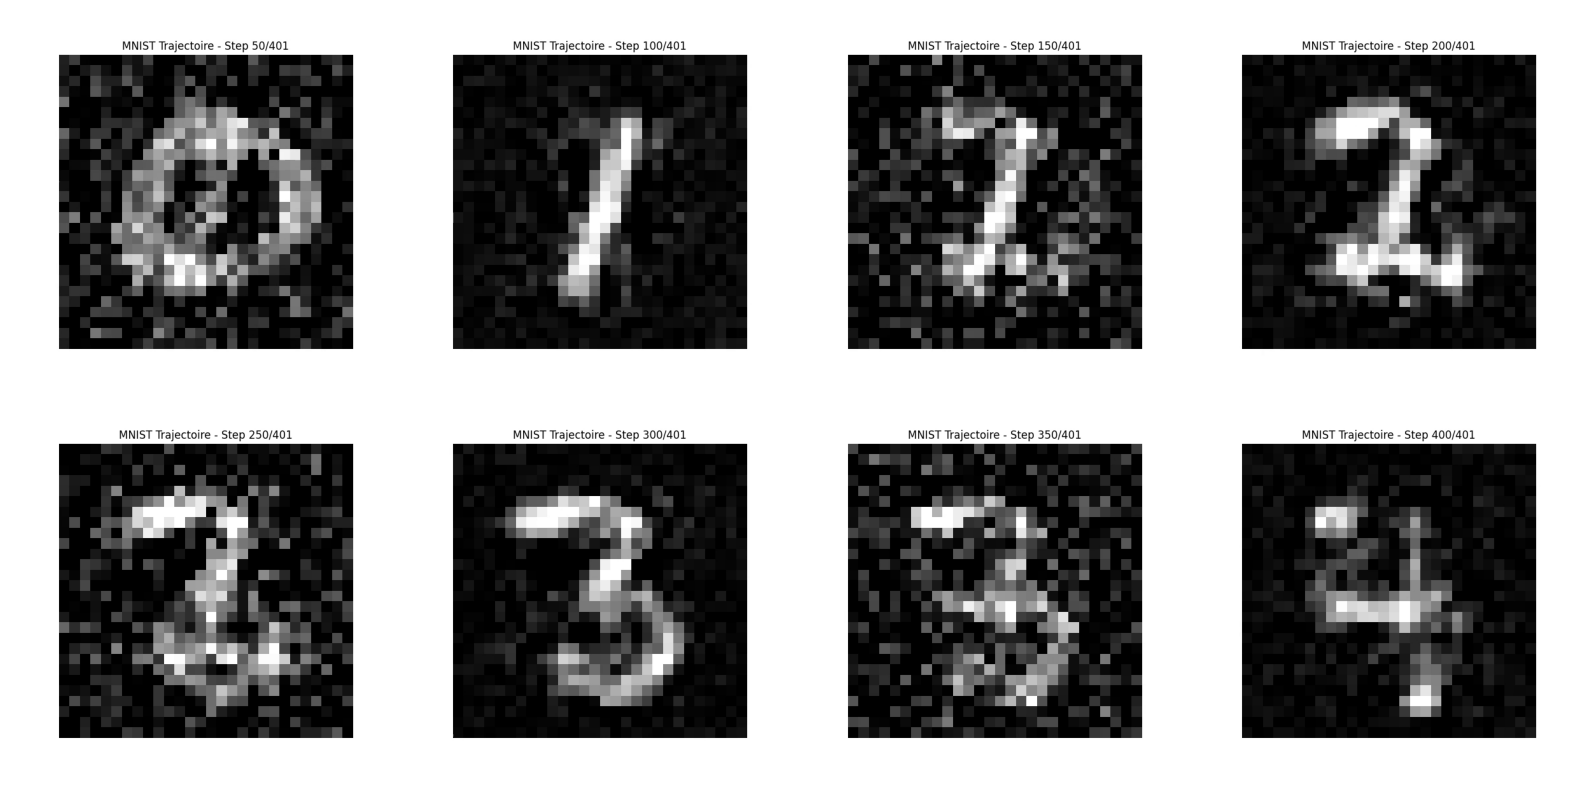

✅ Frames affichées: [50, 100, 150, 200, 250, 300, 350, 400]


In [32]:
# Test avec votre vidéo spécifiée
video_path = "/projects/static2dynamic/Gravier/schron/mnist_trajectory_epoch_0000.mp4"

# Charger l'extracteur
video = VideoFrameExtractor(video_path)

# Afficher les frames de 10 en 10 dans un subplot 4x2 propre
frame_numbers = show_frames_clean_grid(video, start_frame=50, step=50)

print(f"✅ Frames affichées: {frame_numbers}")

In [ ]:
# Autres exemples avec différents paramètres

# Commencer à la frame 20, pas de 15
print("🎬 Frames avec pas de 15, départ frame 20:")
show_frames_clean_grid(video, start_frame=20, step=15)

# Commencer à la frame 50, pas de 20
print("\n🎬 Frames avec pas de 20, départ frame 50:")
show_frames_clean_grid(video, start_frame=50, step=20)

In [ ]:
# Fonction pour choisir manuellement les 8 frames à afficher
def show_custom_frames_grid(video_extractor, frame_numbers, figsize=(16, 8)):
    """
    Affiche exactement 8 frames choisies dans un subplot 4x2 sans titres.

    Args:
        video_extractor: Instance de VideoFrameExtractor
        frame_numbers: Liste de 8 numéros de frames à afficher
        figsize: Taille de la figure
    """
    # Vérifier qu'on a bien 8 frames
    if len(frame_numbers) != 8:
        print(
            f"❌ Erreur: Il faut exactement 8 numéros de frames, vous en avez fourni {len(frame_numbers)}"
        )
        return

    print(f"🎬 Extraction des frames choisies: {frame_numbers}")

    # Créer la figure avec subplot 2x4 (2 lignes, 4 colonnes)
    fig, axes = plt.subplots(2, 4, figsize=figsize)

    # Extraire et afficher chaque frame
    for i, frame_num in enumerate(frame_numbers):
        row = i // 4  # 0 pour les 4 premières, 1 pour les 4 suivantes
        col = i % 4  # 0, 1, 2, 3

        # Extraire la frame
        frame = video_extractor.extract_frame(frame_num)

        if frame is not None:
            # Afficher la frame
            axes[row, col].imshow(frame)
            axes[row, col].axis("off")  # Pas d'axes ni de titres
        else:
            # Si la frame n'existe pas, afficher du noir avec un message
            axes[row, col].imshow(np.zeros((100, 100, 3), dtype=np.uint8))
            axes[row, col].text(
                0.5,
                0.5,
                f"Frame {frame_num}\nNon trouvée",
                transform=axes[row, col].transAxes,
                ha="center",
                va="center",
                color="white",
                fontsize=8,
            )
            axes[row, col].axis("off")
            print(f"⚠️ Frame {frame_num} non trouvée")

    # Ajuster l'espacement
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.02, hspace=0.02)  # Espacement minimal
    plt.show()

    return frame_numbers

🎯 Affichage des frames personnalisées: [0, 16, 20, 33, 50, 65, 81, 97]
🎬 Extraction des frames choisies: [0, 16, 20, 33, 50, 65, 81, 97]


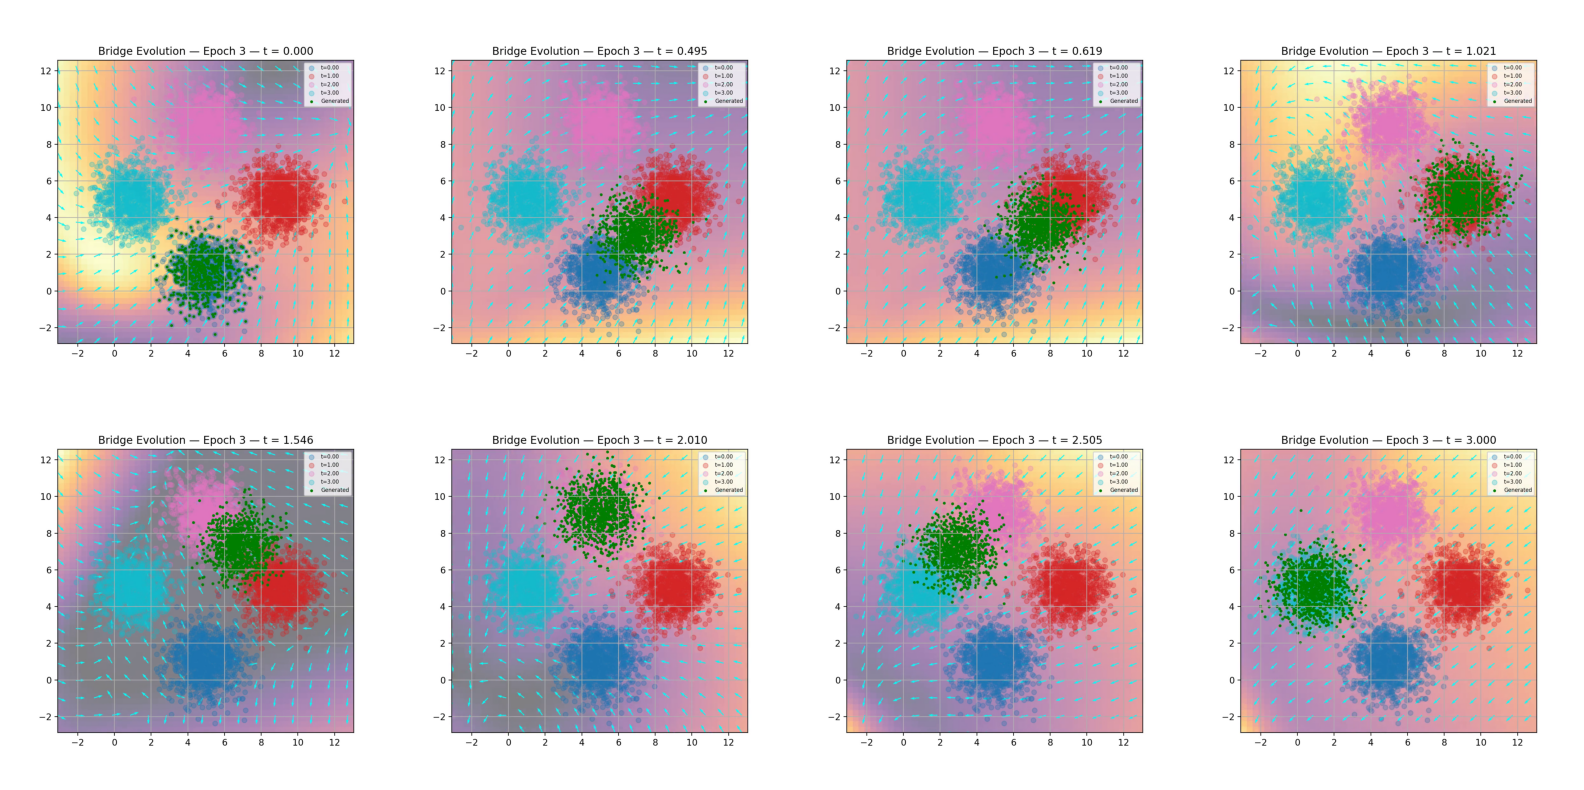

[0, 16, 20, 33, 50, 65, 81, 97]

In [ ]:
# Exemples d'utilisation avec sélection manuelle des frames


# Exemple 1: Frames spécifiques choisies
frames_perso = [0, 16, 20, 33, 50, 65, 81, 97]
print("🎯 Affichage des frames personnalisées:", frames_perso)
show_custom_frames_grid(video, frames_perso)


In [ ]:
# Version interactive pour choisir vos frames facilement
def choose_and_show_frames(video_extractor):
    """
    Version interactive pour choisir et afficher 8 frames.
    """
    print("🎬 Choisissez 8 numéros de frames à afficher")
    print("Entrez les numéros séparés par des virgules (ex: 10,20,30,40,50,60,70,80)")

    # Afficher les infos de la vidéo pour aider
    total_frames = int(video_extractor.duration * video_extractor.fps)
    print(
        f"ℹ️  Info vidéo: ~{total_frames} frames total, durée: {video_extractor.duration:.1f}s"
    )

    user_input = input("Vos 8 frames: ")

    try:
        # Parser l'input
        frame_numbers = [int(x.strip()) for x in user_input.split(",")]

        if len(frame_numbers) != 8:
            print(
                f"❌ Il faut exactement 8 frames, vous en avez fourni {len(frame_numbers)}"
            )
            return

        # Vérifier que les frames sont valides
        max_frame = int(video_extractor.duration * video_extractor.fps) - 1
        valid_frames = []
        for frame in frame_numbers:
            if 0 <= frame <= max_frame:
                valid_frames.append(frame)
            else:
                print(f"⚠️ Frame {frame} hors limites (max: {max_frame})")
                valid_frames.append(min(max(frame, 0), max_frame))

        # Afficher les frames
        show_custom_frames_grid(video_extractor, valid_frames)

    except ValueError:
        print("❌ Format invalide. Utilisez des nombres séparés par des virgules.")


# Décommentez la ligne suivante pour utiliser la version interactive
# Test avec votre vidéo spécifiée
video_path = "/projects/static2dynamic/Gravier/schron/experiments_debug/debug_4gaussian_01/traj_bridges/traj_iter_0_tpairs_[3.0, 0.0]_direction_backward.mp4"

# Charger l'extracteur
video = VideoFrameExtractor(video_path)
choose_and_show_frames(video)

📹 Vidéo chargée: traj_iter_0_tpairs_[3.0, 0.0]_direction_backward.mp4
   - Durée: 4.95 secondes
   - FPS: 20.00
   - Nombre estimé de frames: 99
   - Dimensions: 1200x1200
🎬 Choisissez 8 numéros de frames à afficher
Entrez les numéros séparés par des virgules (ex: 10,20,30,40,50,60,70,80)
ℹ️  Info vidéo: ~99 frames total, durée: 5.0s
❌ Format invalide. Utilisez des nombres séparés par des virgules.
